# Manuscript


### Setup

In [15]:
import pandas as pd
import numpy as np
import os
from tqdm import tqdm
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
from tableone import TableOne

RELEASE_DIR = 'release_data'  # public de-identified inputs (see README)
DERIVED_DIR = 'derived'       # pickles / caches rebuilt by this notebook
os.makedirs(DERIVED_DIR, exist_ok=True)
os.makedirs('manuscript', exist_ok=True)
dtype_dict = {
    "PATIENT_ID": "string",
    "ORDER_ID": "string",
}


In [16]:
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix
from sklearn.metrics import matthews_corrcoef, cohen_kappa_score

classes = [0, 1, 2, 3, 4, 5, 6, 9]
mlb = MultiLabelBinarizer(classes=classes)
mlb.fit([classes])
labels = [
    'No seizure/events', 'Electroclinical seizure', 'Subclinical seizure',
    'Electrographic seizure, clinical unknown', 'Clinical events without EEG correlate',
    'Clinical events, EEG unknown', 'Myoclonus', 'Unclear/Not mentioned',
]

def convert_sum_to_bin(y_sum, n=5):
    half_val = n // 2
    y_true_bin = (y_sum > half_val).astype(int)
    max_class = np.argmax(y_sum, axis=1)
    empty_inds = np.sum(y_true_bin, axis=1) == 0
    y_true_bin[empty_inds, max_class[empty_inds]] = 1
    return y_true_bin


In [17]:
def plot_confusion_matrix_with_counts(
    y_true,
    y_pred,
    labels=None,
    class_names=None,
    ax=None,
    cmap="Blues",
    figsize=(6, 5),
    fmt=".1f"
):
    """
    Plot confusion matrix with row-normalized percentages and raw counts.

    Parameters
    ----------
    y_true : array-like
    y_pred : array-like
    labels : list, optional
        Label order for confusion matrix
    class_names : list, optional
        Names to display on axes
    cmap : str
    figsize : tuple
    fmt : str
        Format for percentage display
    """

    # Compute confusion matrix (counts)
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    # Row-normalized percentages
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_percent = cm / row_sums * 100

    # Build annotation strings
    annot = np.empty_like(cm).astype(str)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            count = cm[i, j]
            percent = cm_percent[i, j]
            annot[i, j] = f"{percent:{fmt}}%\n({count})"

    # Plot
    if ax is None:
        fig, ax = plt.subplots(figsize=figsize)
    else:
        fig = ax.figure
    sns.heatmap(
        cm_percent,
        annot=annot,
        fmt="",
        cmap=cmap,
        ax=ax,
        vmin=0,
        vmax=100,
        cbar=False,
        square=True,
        cbar_kws=None,#{"label": "Percentage (%)"},
        xticklabels=class_names if class_names else labels,
        yticklabels=class_names if class_names else labels
    )
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.5)
        spine.set_color('black')
    return fig, ax


In [18]:
# Score helpers shared with later tables and figures. The bootstrap stays in Calculate scores.
SCORE_ALPHA = 0.05

RATER_PAIRS = [
    ('rater1', 'rater2'), ('Label1', 'Label2'), ('A', 'B'), ('rater_1', 'rater_2'),
    ('Rater1', 'Rater2'), ('annotator1', 'annotator2'), ('Annotator1', 'Annotator2'),
]
CLASS_SCORE_KEYS = [
    'accuracy_class', 'f1_class', 'precision_class', 'recall_class',
    'sensitivity_class', 'specificity_class', 'mcc_class', 'ac1_class', 'kappa_class',
]
SEIZURE_COLS = [1, 2, 3]
EVENT_COLS = [4, 5]
MAJOR_COLS = [0, 1, 2, 4, 6]  # drop columns 3, 5, 7 (classes 3, 5, 9)
FIG2_UNCERTAIN_COLS = [3, 5, 7]  # classes 3, 5, 9


def figure2_class_col_order():
    """Figure 2 x-axis: major classes, then uncertain (3/5/9), then averages."""
    return list(MAJOR_COLS) + list(FIG2_UNCERTAIN_COLS)


def figure2_tick_labels(Y_dev, Y_other=None):
    """Figure 2 x-axis: class label plus consensus-positive n.

    n uses gold-standard consensus labels. If Y_other is given (the comparison
    cohort), ticks show development / other: (n=dev/other).
    """
    Y_dev = np.asarray(Y_dev).astype(int)
    n_dev = int(Y_dev.shape[0])
    c_dev = Y_dev.sum(axis=0).astype(int)
    if Y_other is None:
        fmt = lambda a, b: f"(n={int(a)})"
        n_pair = (n_dev, n_dev)
        c_oth = c_dev
    else:
        Y_other = np.asarray(Y_other).astype(int)
        n_oth = int(Y_other.shape[0])
        c_oth = Y_other.sum(axis=0).astype(int)
        fmt = lambda a, b: f"(n={int(a)}/{int(b)})"
        n_pair = (n_dev, n_oth)
    labels = []
    for j in figure2_class_col_order():
        c = class_inds[j]
        labels.append(f"{class_tick_label(c)}\n{fmt(c_dev[j], c_oth[j])}")
    labels.append(f"Major-class\naverage\n{fmt(*n_pair)}")
    labels.append(f"All-class\naverage\n{fmt(*n_pair)}")
    return labels


def figure2_divider_xpos():
    """Dashed separators: after major block and after uncertain block."""
    n_major = len(MAJOR_COLS)
    n_unc = len(FIG2_UNCERTAIN_COLS)
    return [n_major - 0.5, n_major + n_unc - 0.5]


def figure2_pt_ci(res, class_key, overall_maj, overall_all):
    """Point + CI vectors in Figure 2 x order (major, uncertain, two averages)."""
    pts, los, his = [], [], []
    for j in figure2_class_col_order():
        pts.append(float(res['point'][class_key][j]))
        los.append(float(res['ci'][class_key][0][j]))
        his.append(float(res['ci'][class_key][1][j]))
    for ok in (overall_maj, overall_all):
        if ok in res.get('overall', {}):
            pts.append(float(res['overall'][ok]))
            lo, hi = res['overall_ci'][ok]
            los.append(float(lo))
            his.append(float(hi))
        else:
            pts.append(np.nan)
            los.append(np.nan)
            his.append(np.nan)
    pts, los, his = np.asarray(pts), np.asarray(los), np.asarray(his)
    yerr = np.vstack([np.maximum(0, pts - los), np.maximum(0, his - pts)])
    return pts, yerr

OVER_SCORE_KEYS = [
    'micro_f1', 'macro_f1', 'mcc', 'ac1', 'kappa', 'accuracy_mean',
    'micro_f1_all', 'macro_f1_all', 'mcc_all', 'ac1_all', 'kappa_all', 'accuracy_mean_all',
    'seizure_f1', 'seizure_mcc', 'seizure_ac1', 'seizure_kappa',
    'event_f1', 'event_mcc', 'event_ac1', 'event_kappa',
]
T3_CLASS_FROM_SCORES = {
    'accuracy': 'accuracy_class', 'f1': 'f1_class', 'precision': 'precision_class',
    'recall': 'recall_class', 'specificity': 'specificity_class', 'mcc': 'mcc_class', 'ac1': 'ac1_class',
    'kappa': 'kappa_class',
}
T3_OVER_FROM_SCORES = {
    'micro_f1': 'micro_f1', 'macro_f1': 'macro_f1', 'accuracy_mean': 'accuracy_mean',
    'ac1_mean': 'ac1', 'mcc_mean': 'mcc', 'kappa_mean': 'kappa',
    'micro_f1_all': 'micro_f1_all', 'macro_f1_all': 'macro_f1_all',
    'accuracy_mean_all': 'accuracy_mean_all', 'ac1_mean_all': 'ac1_all', 'mcc_mean_all': 'mcc_all',
    'kappa_mean_all': 'kappa_all',
    'seizure_f1': 'seizure_f1', 'seizure_mcc': 'seizure_mcc', 'seizure_ac1': 'seizure_ac1',
    'seizure_kappa': 'seizure_kappa',
    'event_f1': 'event_f1', 'event_mcc': 'event_mcc', 'event_ac1': 'event_ac1',
    'event_kappa': 'event_kappa',
}
EXTRA_TABLE_ROWS = [
    ('Seizure (1–3)', 'Any class 1–3', 'seizure_f1', 'seizure_mcc', 'seizure_ac1', 'seizure_kappa'),
    ('Event (4–5)', 'Any class 4–5', 'event_f1', 'event_mcc', 'event_ac1', 'event_kappa'),
]


def gwet_ac1(y1, y2):
    """Gwet's AC1 for two binary raters (q=2)."""
    y1 = np.asarray(y1).ravel()
    y2 = np.asarray(y2).ravel()
    n = y1.size
    if n == 0:
        return np.nan
    po = np.mean(y1 == y2)
    pi1 = 0.5 * (np.mean(y1) + np.mean(y2))
    pe = 2 * pi1 * (1.0 - pi1)
    denom = 1.0 - pe
    if np.isclose(denom, 0.0):
        return 1.0 if np.isclose(po, 1.0) else np.nan
    return (po - pe) / denom


def _corr_defined(tn, fp, fn, tp):
    """MCC/kappa are undefined if any 2x2 margin is 0 (all-0 class, constant prediction, etc.)."""
    return min(tp + fp, tp + fn, tn + fp, tn + fn) > 0


def binary_metrics(y, yhat):
    y = np.asarray(y).ravel().astype(int)
    yhat = np.asarray(yhat).ravel().astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    if _corr_defined(tn, fp, fn, tp):
        mcc = float(matthews_corrcoef(y, yhat))
        kappa = float(cohen_kappa_score(y, yhat))
        if not np.isfinite(mcc):
            mcc = np.nan
        if not np.isfinite(kappa):
            kappa = np.nan
    else:
        mcc, kappa = np.nan, np.nan
    return {
        'accuracy': float(accuracy_score(y, yhat)),
        'f1': (np.nan if (tp + fn) == 0 else float(f1_score(y, yhat, zero_division=0))),
        'precision': (np.nan if (tp + fp) == 0 else float(prec)),
        'recall': (np.nan if (tp + fn) == 0 else float(rec)),
        'specificity': float(spec),
        'mcc': mcc,
        'ac1': float(gwet_ac1(y, yhat)),
        'kappa': kappa,
        'micro_f1': float(f1_score(y, yhat, average='micro', zero_division=0)),
    }


def _or_bin(Y, cols):
    Y = np.asarray(Y).astype(int)
    return Y[:, list(cols)].any(axis=1).astype(int)


def overall_metrics(Y, Yhat):
    Y = np.asarray(Y).astype(int)
    Yhat = np.asarray(Yhat).astype(int)
    per = [binary_metrics(Y[:, j], Yhat[:, j]) for j in range(Y.shape[1])]
    maj = [j for j in MAJOR_COLS if j < Y.shape[1]]
    per_maj = [per[j] for j in maj]
    sz = binary_metrics(_or_bin(Y, SEIZURE_COLS), _or_bin(Yhat, SEIZURE_COLS))
    ev = binary_metrics(_or_bin(Y, EVENT_COLS), _or_bin(Yhat, EVENT_COLS))
    Ym, Yhm = Y[:, maj], Yhat[:, maj]
    return {
        'micro_f1': float(f1_score(Ym, Yhm, average='micro', zero_division=0)),
        'macro_f1': float(np.nanmean([p['f1'] for p in per_maj])),
        'accuracy_mean': float(np.mean([p['accuracy'] for p in per_maj])),
        'ac1_mean': float(np.nanmean([p['ac1'] for p in per_maj])),
        'mcc_mean': float(np.nanmean([p['mcc'] for p in per_maj])),
        'kappa_mean': float(np.nanmean([p['kappa'] for p in per_maj])),
        'micro_f1_all': float(f1_score(Y, Yhat, average='micro', zero_division=0)),
        'macro_f1_all': float(np.nanmean([p['f1'] for p in per])),
        'accuracy_mean_all': float(np.mean([p['accuracy'] for p in per])),
        'ac1_mean_all': float(np.nanmean([p['ac1'] for p in per])),
        'mcc_mean_all': float(np.nanmean([p['mcc'] for p in per])),
        'kappa_mean_all': float(np.nanmean([p['kappa'] for p in per])),
        'seizure_f1': sz['f1'], 'seizure_mcc': sz['mcc'], 'seizure_ac1': sz['ac1'], 'seizure_kappa': sz['kappa'],
        'event_f1': ev['f1'], 'event_mcc': ev['mcc'], 'event_ac1': ev['ac1'], 'event_kappa': ev['kappa'],
    }


def metrics_from_pair(Y, Yhat):
    """Per-class and overall metrics for one label pair. No aggregation across pairs."""
    Y = np.asarray(Y).astype(int)
    Yhat = np.asarray(Yhat).astype(int)
    d = Y.shape[1]
    class_m = {k: np.zeros(d, dtype=float) for k in CLASS_SCORE_KEYS}
    for j in range(d):
        m = binary_metrics(Y[:, j], Yhat[:, j])
        class_m['accuracy_class'][j] = m['accuracy']
        class_m['f1_class'][j] = m['f1']
        class_m['precision_class'][j] = m['precision']
        class_m['recall_class'][j] = m['recall']
        class_m['sensitivity_class'][j] = m['recall']
        class_m['specificity_class'][j] = m['specificity']
        class_m['mcc_class'][j] = m['mcc']
        class_m['ac1_class'][j] = m['ac1']
        class_m['kappa_class'][j] = m['kappa']
    over = overall_metrics(Y, Yhat)
    over_m = {
        'micro_f1': over['micro_f1'],
        'macro_f1': over['macro_f1'],
        'mcc': over['mcc_mean'],
        'ac1': over['ac1_mean'],
        'kappa': over['kappa_mean'],
        'accuracy_mean': over['accuracy_mean'],
        'micro_f1_all': over['micro_f1_all'],
        'macro_f1_all': over['macro_f1_all'],
        'mcc_all': over['mcc_mean_all'],
        'ac1_all': over['ac1_mean_all'],
        'kappa_all': over['kappa_mean_all'],
        'accuracy_mean_all': over['accuracy_mean_all'],
        'seizure_f1': over['seizure_f1'],
        'seizure_mcc': over['seizure_mcc'],
        'seizure_ac1': over['seizure_ac1'],
        'seizure_kappa': over['seizure_kappa'],
        'event_f1': over['event_f1'],
        'event_mcc': over['event_mcc'],
        'event_ac1': over['event_ac1'],
        'event_kappa': over['event_kappa'],
    }
    return class_m, over_m


def stack_pair_scores(pairs):
    n_pairs = len(pairs)
    d = np.asarray(pairs[0][0]).shape[1]
    class_out = {k: np.zeros((n_pairs, d), dtype=float) for k in CLASS_SCORE_KEYS}
    over_out = {k: np.zeros(n_pairs, dtype=float) for k in OVER_SCORE_KEYS}
    for p, (Y, Yhat) in enumerate(pairs):
        cm, om = metrics_from_pair(Y, Yhat)
        for k in CLASS_SCORE_KEYS:
            class_out[k][p] = cm[k]
        for k in OVER_SCORE_KEYS:
            over_out[k][p] = om[k]
    out = {}
    out.update(over_out)
    out.update(class_out)
    return out


def _parse_multilabel(x):
    if pd.isna(x):
        return []
    if isinstance(x, (int, np.integer, float, np.floating)) and not isinstance(x, bool):
        if isinstance(x, (float, np.floating)) and not np.isfinite(x):
            return []
        return [int(x)]
    return [int(i.strip()) for i in str(x).split(',') if str(i).strip() not in ('', 'nan', 'None')]


def _read_table(path):
    path = str(path)
    df = pd.read_excel(path) if path.lower().endswith(('.xlsx', '.xls')) else pd.read_csv(path, dtype=dtype_dict)
    if 'ORDER_ID' in df.columns:
        df['ORDER_ID'] = df['ORDER_ID'].astype(str)
    return df


def _to_bin(series):
    if getattr(mlb, 'classes_', None) is None:
        mlb.fit([[c] for c in class_inds])
    return mlb.transform(series.map(_parse_multilabel).tolist()).astype(int)


def _load_val(sample_path, annot_path):
    sample = _read_table(sample_path)
    try:
        annot = _read_table(annot_path)
    except FileNotFoundError:
        annot = None
    if annot is not None:
        overlap = [c for c in annot.columns if c != 'ORDER_ID' and c not in sample.columns]
        sample = sample.merge(annot[['ORDER_ID'] + overlap].drop_duplicates('ORDER_ID'), on='ORDER_ID', how='left')
    sample = sample.copy()
    sample['ORDER_ID'] = sample['ORDER_ID'].astype(str)
    if 'pred_class' not in sample.columns:
        pred_src = nlp_df[['ORDER_ID', 'pred_class']].drop_duplicates('ORDER_ID').copy()
        pred_src['ORDER_ID'] = pred_src['ORDER_ID'].astype(str)
        sample = sample.merge(pred_src, on='ORDER_ID', how='left')
    sample['pred_class'] = sample['pred_class'].fillna('0')
    return sample


def _prep_two_rater_val(sample_path, annot_path, name='val'):
    """Two-rater test set: rater_1/rater_2 + consensus `label` + model pred."""
    df = _load_val(sample_path, annot_path)
    rater_cols = _detect_rater_cols(df)
    if rater_cols is None:
        raise ValueError(f'{name} needs two annotator columns (rater_1/rater_2). Found: {list(df.columns)}')
    r1, r2 = rater_cols
    df = df.dropna(subset=[r1, r2]).drop_duplicates('ORDER_ID').reset_index(drop=True)
    Ya = _to_bin(df[r1])
    Yb = _to_bin(df[r2])
    Y_cons = _to_bin(df['label']) if 'label' in df.columns else convert_sum_to_bin(Ya + Yb, n=2)
    Yhat = _to_bin(df['pred_class'])
    scores_human = stack_pair_scores([(Ya, Yb)])
    scores_model = stack_pair_scores([(Y_cons, Yhat)])
    print(f'{name} full-data: n={Ya.shape[0]}  raters={r1!r}, {r2!r}  n_pairs=1')
    return {
        'df': df, 'Y1': Ya, 'Y2': Yb, 'Y_cons': Y_cons, 'Yhat': Yhat,
        'scores_human': scores_human, 'scores_model': scores_model,
        'n': int(Ya.shape[0]),
    }


def _assign_val_globals(prefix, block):
    """Load test set (n=100) score arrays into globals."""
    if prefix != 'val2':
        raise ValueError(f'unexpected cohort prefix {prefix!r}')
    g = globals()
    g['scores_val2_human'] = block['scores_human']
    g['scores_val2_model'] = block['scores_model']
    g['scores_val2_human_bs'] = block.get('scores_human_bs')
    g['scores_val2_model_bs'] = block.get('scores_model_bs')
    g['Y1_val2'] = block['Y1']
    g['Y2_val2'] = block['Y2']
    g['Y_cons2'] = block['Y_cons']
    g['Yhat2'] = block.get('Yhat', block.get('Yhat1'))


def _detect_rater_cols(df):
    for a, b in RATER_PAIRS:
        if a in df.columns and b in df.columns:
            return a, b
    return None


def fmt_ci(pt, lo, hi, digits=2):
    if not np.isfinite(pt):
        return 'NA'
    if not np.isfinite(lo) or not np.isfinite(hi):
        return f'{pt:.{digits}f}'
    return f'{pt:.{digits}f} [{lo:.{digits}f},{hi:.{digits}f}]'


def _boot_ci_1d(boot, alpha=SCORE_ALPHA):
    lo_q, hi_q = 100 * alpha / 2, 100 * (1 - alpha / 2)
    x = np.asarray(boot, dtype=float).ravel()
    x = x[np.isfinite(x)]
    if x.size == 0:
        return (np.nan, np.nan)
    return (float(np.percentile(x, lo_q)), float(np.percentile(x, hi_q)))


def _mean_class_ci(res, key, cols=None, alpha=SCORE_ALPHA):
    """Macro-mean of a per-class score, with bootstrap percentile CI."""
    pt_arr = np.asarray(res['point'][key], dtype=float)
    boot = np.asarray(res['boot_class'][key], dtype=float)
    if cols is not None:
        cols = list(cols)
        pt_arr = pt_arr[cols]
        boot = boot[:, cols]
    pt = float(np.nanmean(pt_arr))
    lo, hi = _boot_ci_1d(np.nanmean(boot, axis=1), alpha=alpha)
    return pt, lo, hi


def metrics_table(res, name):
    rows = []
    for j, c in enumerate(class_inds):
        row = {
            'comparison': name,
            'Class': class_name(c),
            'Label': short_class_labels.get(c, str(c)).replace('\n', ' '),
        }
        for k in res['point']:
            row[k] = res['point'][k][j]
            row[f'{k}_ci'] = fmt_ci(res['point'][k][j], res['ci'][k][0][j], res['ci'][k][1][j])
        rows.append(row)
    for spec in EXTRA_TABLE_ROWS:
        cls, lab, fk, mk, ak, *rest = spec
        row = {'comparison': name, 'Class': cls, 'Label': lab}
        dests = [('f1', fk), ('mcc', mk), ('ac1', ak)]
        if rest:
            dests.append(('kappa', rest[0]))
        for dest, src_k in dests:
            if src_k not in res.get('overall', {}):
                continue
            pt = res['overall'][src_k]
            lo, hi = res['overall_ci'][src_k]
            row[dest] = pt
            row[f'{dest}_ci'] = fmt_ci(pt, lo, hi)
        rows.append(row)
    row = {'comparison': name, 'Class': 'Overall', 'Label': 'all classes'}
    if 'macro_f1_all' in res.get('overall', {}):
        pt, (lo, hi) = res['overall']['macro_f1_all'], res['overall_ci']['macro_f1_all']
        row['f1'] = pt
        row['f1_ci'] = fmt_ci(pt, lo, hi)
        pt, (lo, hi) = res['overall']['mcc_mean_all'], res['overall_ci']['mcc_mean_all']
        row['mcc'] = pt
        row['mcc_ci'] = fmt_ci(pt, lo, hi)
        pt, (lo, hi) = res['overall']['ac1_mean_all'], res['overall_ci']['ac1_mean_all']
        row['ac1'] = pt
        row['ac1_ci'] = fmt_ci(pt, lo, hi)
        if 'kappa_mean_all' in res['overall']:
            pt, (lo, hi) = res['overall']['kappa_mean_all'], res['overall_ci']['kappa_mean_all']
            row['kappa'] = pt
            row['kappa_ci'] = fmt_ci(pt, lo, hi)
    else:
        for dest, src_k in [('f1', 'f1'), ('mcc', 'mcc'), ('ac1', 'ac1'), ('kappa', 'kappa')]:
            if src_k not in res.get('point', {}):
                continue
            pt, lo, hi = _mean_class_ci(res, src_k)
            row[dest] = pt
            row[f'{dest}_ci'] = fmt_ci(pt, lo, hi)
    rows.append(row)
    row = {'comparison': name, 'Class': 'Overall (0, 1, 2, 4, 6)', 'Label': 'major classes 0, 1, 2, 4, 6'}
    if 'macro_f1' in res['overall']:
        pt, (lo, hi) = res['overall']['macro_f1'], res['overall_ci']['macro_f1']
        row['f1'] = pt
        row['f1_ci'] = fmt_ci(pt, lo, hi)
    if 'mcc_mean' in res['overall']:
        pt, (lo, hi) = res['overall']['mcc_mean'], res['overall_ci']['mcc_mean']
        row['mcc'] = pt
        row['mcc_ci'] = fmt_ci(pt, lo, hi)
    if 'ac1_mean' in res['overall']:
        pt, (lo, hi) = res['overall']['ac1_mean'], res['overall_ci']['ac1_mean']
        row['ac1'] = pt
        row['ac1_ci'] = fmt_ci(pt, lo, hi)
    if 'kappa_mean' in res['overall']:
        pt, (lo, hi) = res['overall']['kappa_mean'], res['overall_ci']['kappa_mean']
        row['kappa'] = pt
        row['kappa_ci'] = fmt_ci(pt, lo, hi)
    for k in ['micro_f1', 'macro_f1', 'accuracy_mean', 'mcc_mean', 'ac1_mean', 'kappa_mean']:
        if k not in res['overall']:
            continue
        pt = res['overall'][k]
        row[k] = pt
        row[f'{k}_ci'] = fmt_ci(pt, res['overall_ci'][k][0], res['overall_ci'][k][1])
    rows.append(row)
    return pd.DataFrame(rows)


def make_res_human(scores, scores_bs, alpha=SCORE_ALPHA):
    """Median across pairs, then bootstrap percentile CI. Pair axis is kept in the saved arrays."""
    lo_q, hi_q = 100 * alpha / 2, 100 * (1 - alpha / 2)
    point, ci, boot_class = {}, {}, {}
    for k, sk in T3_CLASS_FROM_SCORES.items():
        if sk not in scores or sk not in scores_bs:
            continue
        pt = np.nanmedian(np.asarray(scores[sk], dtype=float), axis=0)
        boot = np.nanmedian(scores_bs[sk], axis=1)
        point[k] = pt
        boot_class[k] = boot
        ci[k] = (np.nanpercentile(boot, lo_q, axis=0), np.nanpercentile(boot, hi_q, axis=0))
    overall, overall_ci, boot_over = {}, {}, {}
    for k, sk in T3_OVER_FROM_SCORES.items():
        if sk not in scores or sk not in scores_bs:
            continue
        pt = float(np.nanmedian(np.asarray(scores[sk], dtype=float)))
        boot = np.nanmedian(scores_bs[sk], axis=1)
        overall[k] = pt
        boot_over[k] = boot
        overall_ci[k] = _boot_ci_1d(boot, alpha=alpha)
    return {'point': point, 'ci': ci, 'overall': overall, 'overall_ci': overall_ci,
            'boot_class': boot_class, 'boot_over': boot_over}


def make_res_model(scores, scores_bs, cons_index=-1, alpha=SCORE_ALPHA):
    lo_q, hi_q = 100 * alpha / 2, 100 * (1 - alpha / 2)
    point, ci, boot_class = {}, {}, {}
    for k, sk in T3_CLASS_FROM_SCORES.items():
        if sk not in scores or sk not in scores_bs:
            continue
        arr = np.asarray(scores[sk], dtype=float)
        pt = arr[cons_index] if arr.ndim == 2 else arr
        boot = scores_bs[sk][:, cons_index, :] if scores_bs[sk].ndim == 3 else scores_bs[sk]
        point[k] = np.asarray(pt, dtype=float)
        boot_class[k] = boot
        ci[k] = (np.nanpercentile(boot, lo_q, axis=0), np.nanpercentile(boot, hi_q, axis=0))
    overall, overall_ci, boot_over = {}, {}, {}
    for k, sk in T3_OVER_FROM_SCORES.items():
        if sk not in scores or sk not in scores_bs:
            continue
        arr = np.asarray(scores[sk], dtype=float)
        pt = float(arr[cons_index] if arr.ndim == 1 else arr)
        boot = scores_bs[sk][:, cons_index] if scores_bs[sk].ndim == 2 else scores_bs[sk]
        overall[k] = pt
        boot_over[k] = boot
        overall_ci[k] = _boot_ci_1d(boot, alpha=alpha)
    return {'point': point, 'ci': ci, 'overall': overall, 'overall_ci': overall_ci,
            'boot_class': boot_class, 'boot_over': boot_over}


def _p_from_boots(h, m):
    mask = np.isfinite(h) & np.isfinite(m)
    if not np.any(mask):
        return np.nan, np.nan
    return float(np.mean(m[mask] >= h[mask])), float(np.mean(h[mask] > m[mask]))


def _diff_ci_from_boots(h, m, alpha=SCORE_ALPHA):
    """Percentile 95% CI of paired (model - human) bootstrap differences."""
    return _boot_ci_1d(np.asarray(m, dtype=float) - np.asarray(h, dtype=float), alpha=alpha)


def _obs_diff(h_pt, m_pt):
    if np.isfinite(h_pt) and np.isfinite(m_pt):
        return float(m_pt - h_pt)
    return np.nan


def compare_human_model_pvalues(human_res, model_res):
    p_not_worse, p_human_better = {}, {}
    p_not_worse_over, p_human_better_over = {}, {}
    diff_pt, diff_lo, diff_hi = {}, {}, {}
    diff_pt_over, diff_lo_over, diff_hi_over = {}, {}, {}
    for k in human_res['boot_class']:
        nw, hb = [], []
        dpt, dlo, dhi = [], [], []
        for j in range(human_res['boot_class'][k].shape[1]):
            h_b = human_res['boot_class'][k][:, j]
            m_b = model_res['boot_class'][k][:, j]
            a, b = _p_from_boots(h_b, m_b)
            nw.append(a)
            hb.append(b)
            dpt.append(_obs_diff(human_res['point'][k][j], model_res['point'][k][j]))
            lo, hi = _diff_ci_from_boots(h_b, m_b)
            dlo.append(lo)
            dhi.append(hi)
        p_not_worse[k] = np.array(nw, dtype=float)
        p_human_better[k] = np.array(hb, dtype=float)
        diff_pt[k] = np.array(dpt, dtype=float)
        diff_lo[k] = np.array(dlo, dtype=float)
        diff_hi[k] = np.array(dhi, dtype=float)
    for k in human_res['boot_over']:
        h_b = human_res['boot_over'][k]
        m_b = model_res['boot_over'][k]
        a, b = _p_from_boots(h_b, m_b)
        p_not_worse_over[k] = a
        p_human_better_over[k] = b
        diff_pt_over[k] = _obs_diff(human_res['overall'].get(k, np.nan), model_res['overall'].get(k, np.nan))
        lo, hi = _diff_ci_from_boots(h_b, m_b)
        diff_lo_over[k] = lo
        diff_hi_over[k] = hi
    return {
        'p_model_not_worse': p_not_worse,
        'p_human_better': p_human_better,
        'p_model_not_worse_overall': p_not_worse_over,
        'p_human_better_overall': p_human_better_over,
        'diff_pt': diff_pt,
        'diff_lo': diff_lo,
        'diff_hi': diff_hi,
        'diff_pt_overall': diff_pt_over,
        'diff_lo_overall': diff_lo_over,
        'diff_hi_overall': diff_hi_over,
    }


### Build predictions from 5 runs

Reads the released prediction tables in `release_data/`.

- `pred_by_run_<set>.csv` has one row per note and class: `runs_0`–`runs_4` are the cleaned answers (class 0 is already flipped) and `consensus` is the majority vote before the exclusion rules.
- `pred_consensus_<set>.csv` has one row per note and one column per class (`Class0`, `Class1`, `Class2`, `Class3`, `Class4`, `Class5`, `Class6`, `Class9`): the consensus after the exclusion rules. `<set>` is `dev`, `test`, or `nlp`. NLP notes the model did not score are class 0. The full cohort uses the NLP consensus, and every order outside that set is class 0.

Each individual run is passed through the development/test exclusion rules. Class 9 on the five-run vote is cleared before those rules. The stored consensus table is checked against that vote. Development-set consensus labels are the majority of the five raters; a note with no majority class gets its most-voted class.

Writes `derived/dev_data.pkl` and `derived/test_data.pkl`, each `[y_phys, y_phys_bin, y_true, y_true_bin, y_ds, y_ds_bin, full_pred]`.


In [4]:
N_REPS = 5
RUN_COLS = [f'runs_{r}' for r in range(N_REPS)]
CLASS_COLS = [f'Class{c}' for c in classes]


def load_by_run(path, order_ids):
    """Per-run binary matrices (n_notes x 8) from pred_by_run_*.csv, aligned to order_ids."""
    df = pd.read_csv(path, dtype={'ORDER_ID': str})
    df.columns = [str(c) for c in df.columns]
    df['class'] = df['class'].astype(int)
    order_ids = pd.Index(pd.Series(order_ids).astype(str))
    missing = order_ids.difference(df['ORDER_ID'])
    if len(missing):
        raise ValueError(f'{path}: {len(missing)} notes are missing')
    by_rep = []
    for col in RUN_COLS:
        one = []
        for c in classes:
            s = df.loc[df['class'] == c].drop_duplicates('ORDER_ID').set_index('ORDER_ID')[col]
            vals = s.reindex(order_ids)
            if vals.isna().any():
                raise ValueError(f'{path}: {int(vals.isna().sum())} notes are missing {col} for class {c}')
            one.append(vals.to_numpy(dtype=float))
        by_rep.append(np.vstack(one).T)
    return by_rep


def load_consensus(path, order_ids):
    """Post-processed consensus from pred_consensus_*.csv, rows aligned to order_ids."""
    df = pd.read_csv(path, dtype={'ORDER_ID': str})
    df.columns = [str(c) for c in df.columns]
    order_ids = pd.Index(pd.Series(order_ids).astype(str))
    df = df.drop_duplicates('ORDER_ID').set_index('ORDER_ID').reindex(order_ids)
    if df[CLASS_COLS].isna().any().any():
        raise ValueError(f'{path}: {int(df[CLASS_COLS].isna().any(axis=1).sum())} notes are missing')
    return df[CLASS_COLS].to_numpy(dtype=int)


def labels_from_consensus(path, order_ids):
    labels = []
    for y in mlb.inverse_transform(load_consensus(path, order_ids)):
        labels.append(','.join(str(i) for i in y) if len(y) else '0')
    return labels


def apply_rules_annot(Y):
    Y = np.asarray(Y).copy()
    for i in range(Y.shape[0]):
        if np.sum(Y[i, :]) == 0:
            Y[i, -1] = 1
        if Y[i, 0] == 1:
            Y[i, np.r_[2, 3, 5, 7]] = 0
        if np.any(Y[i, np.r_[1, 4, 6]]):
            Y[i, 0] = 0
        if np.any(Y[i, np.r_[1, 2]] == 1):
            Y[i, 3] = 0
        if np.any(Y[i, :-1]):
            Y[i, -1] = 0
    return Y


def consensus_from_runs(runs, clear_class9_vote=False):
    vote = convert_sum_to_bin(np.sum(runs, axis=0))
    if clear_class9_vote:
        vote = vote.copy()
        vote[:, -1] = 0
    return apply_rules_annot(vote)


def parse_labels(series):
    return series.map(lambda x: [int(i.strip(' ')) for i in x.split(',')] if isinstance(x, str) else [x]).to_numpy()


def parse_label_cell(x):
    if pd.isna(x):
        return [0]
    parts = [i.strip() for i in str(x).split(',') if i.strip() not in ('', 'nan', 'None')]
    return [int(i) for i in parts] if parts else [0]


# --- Development set: 5 raters + 5 runs ---
annot_dev = pd.read_csv(f'{RELEASE_DIR}/annot_dev.csv', dtype=str)
y_phys, y_phys_bin = [], []
for col in ['Label1', 'Label2', 'Label3', 'Label4', 'Label5']:
    labs = parse_labels(annot_dev[col])
    y_phys.append(labs)
    y_phys_bin.append(mlb.fit_transform(labs))
y_true_bin = convert_sum_to_bin(np.sum(y_phys_bin, axis=0), n=len(y_phys))
y_true = mlb.inverse_transform(y_true_bin)
runs_dev = load_by_run(f'{RELEASE_DIR}/pred_by_run_dev.csv', annot_dev['ORDER_ID'])
full_pred = load_consensus(f'{RELEASE_DIR}/pred_consensus_dev.csv', annot_dev['ORDER_ID'])
if not np.array_equal(full_pred, consensus_from_runs(runs_dev, clear_class9_vote=True)):
    raise ValueError('pred_consensus_dev.csv does not match the runs after the exclusion rules')
y_ds_bin = [apply_rules_annot(Y) for Y in runs_dev]
y_ds = [mlb.inverse_transform(Y) for Y in y_ds_bin]
with open(f'{DERIVED_DIR}/dev_data.pkl', 'wb') as f:
    pickle.dump([y_phys, y_phys_bin, y_true, y_true_bin, y_ds, y_ds_bin, full_pred], f)

# --- Test set: 2 raters + consensus label; runs are the released test-set runs ---
annot_test = pd.read_csv(f'{RELEASE_DIR}/annot_test.csv', dtype=str)
runs_test = load_by_run(f'{RELEASE_DIR}/pred_by_run_test.csv', annot_test['ORDER_ID'])
full_pred_t = load_consensus(f'{RELEASE_DIR}/pred_consensus_test.csv', annot_test['ORDER_ID'])
if not np.array_equal(full_pred_t, consensus_from_runs(runs_test, clear_class9_vote=True)):
    raise ValueError('pred_consensus_test.csv does not match the runs after the exclusion rules')
y_ds_bin_t = [apply_rules_annot(Y) for Y in runs_test]
y_ds_t = [mlb.inverse_transform(Y) for Y in y_ds_bin_t]
y_phys_t = [annot_test[c].map(parse_label_cell).to_numpy() for c in ['rater_1', 'rater_2']]
y_phys_bin_t = [mlb.transform(list(labs)).astype(int) for labs in y_phys_t]
y_true_bin_t = mlb.transform(annot_test['label'].map(parse_label_cell).tolist()).astype(int)
y_true_t = mlb.inverse_transform(y_true_bin_t)
with open(f'{DERIVED_DIR}/test_data.pkl', 'wb') as f:
    pickle.dump([y_phys_t, y_phys_bin_t, y_true_t, y_true_bin_t, y_ds_t, y_ds_bin_t, full_pred_t], f)

print(f'development: n={y_true_bin.shape[0]}  raters={len(y_phys)}  runs={len(y_ds_bin)}')
print(f'test: n={y_true_bin_t.shape[0]}  raters=2  runs={len(y_ds_bin_t)}')
print(f'saved {DERIVED_DIR}/dev_data.pkl, {DERIVED_DIR}/test_data.pkl')


development: n=166  raters=5  runs=5
test: n=100  raters=2  runs=5
saved derived/dev_data.pkl, derived/test_data.pkl


### Manuscript figures/tables

In [ ]:
seizure_orders = pd.read_csv(f'{RELEASE_DIR}/orders.csv', dtype=dtype_dict)
for col in ['nlp', 'development', 'test']:
    seizure_orders[col] = seizure_orders[col].astype(int).astype(bool)
nlp_df = seizure_orders.loc[seizure_orders['nlp'], ['ORDER_ID']].reset_index(drop=True)
annot_df = pd.read_csv(f'{RELEASE_DIR}/annot_dev.csv', dtype=dtype_dict)[['ORDER_ID']]
with open(f'{DERIVED_DIR}/dev_data.pkl','rb') as f:
    y_phys, y_phys_bin, y_true, y_true_bin, y_ds,y_ds_bin, full_pred = pickle.load(f)
y_true_bin_df = pd.DataFrame(y_true_bin, columns=['Class_'+str(i) for i in classes])
y_pred = mlb.inverse_transform(full_pred)
annot_df['pred_class'] = [','.join([str(i) for i in y]) for y in y_pred]
annot_df['pred_class'] = annot_df['pred_class'].fillna('0')
y_bin_df = pd.DataFrame(full_pred, columns=['Class'+str(c) for c in classes])

nlp_df['pred_class'] = labels_from_consensus(f'{RELEASE_DIR}/pred_consensus_nlp.csv', nlp_df['ORDER_ID'])
y_bin_nlp = nlp_df['pred_class'].to_list()
y_bin_nlp = [[int(i) for i in y.split(',')] for y in y_bin_nlp]
y_bin_nlp = mlb.transform(y_bin_nlp)
y_bin_nlp_df = pd.DataFrame(y_bin_nlp, columns=['Class'+str(c) for c in classes])
y_bin_nlp_df['ORDER_ID'] = nlp_df['ORDER_ID']

seizure_orders = seizure_orders.merge(nlp_df[['ORDER_ID', 'pred_class']], on='ORDER_ID', how='left')
seizure_orders['pred_class'] = seizure_orders['pred_class'].fillna('0')
y_bin_full = seizure_orders['pred_class'].to_list()
y_bin_full = [[int(i) for i in y.split(',')] for y in y_bin_full]
y_bin_full = mlb.transform(y_bin_full)
y_bin_full_df = pd.DataFrame(y_bin_full, columns=['Class'+str(c) for c in classes])
y_bin_full_df['ORDER_ID'] = seizure_orders['ORDER_ID']
seizure_orders = seizure_orders.merge(y_bin_full_df, on='ORDER_ID', how='left')

def _load_scores_bootstrap(path=f'{DERIVED_DIR}/scores_bootstrap.pkl'):
    with open(path, 'rb') as f:
        obj = pickle.load(f)
    if isinstance(obj, dict):
        return obj
    sp, sd, spb, sdb = obj
    return {'scores_phys': sp, 'scores_ds': sd, 'scores_phys_bs': spb, 'scores_ds_bs': sdb, 'val2': None}

if os.path.exists(f'{DERIVED_DIR}/scores_bootstrap.pkl'):  # otherwise built in Calculate scores
    scores_bundle = _load_scores_bootstrap()
    scores_phys = scores_bundle['scores_phys']
    scores_ds = scores_bundle['scores_ds']
    scores_phys_bs = scores_bundle['scores_phys_bs']
    scores_ds_bs = scores_bundle['scores_ds_bs']

class_inds = [0,1,2,3,4,5,6,9]
class_labels = {0:'No seizure/event', 1:'Electroclinical seizure', 2:'Subclinical seizure',3:'Electrographic seizure\nClinical unknown',
                4:'Clinical event\nwithout EEG',5:'Clinical event\nEEG unknown',6:'Myoclonus',9:'Uncertain'}
short_class_labels = {0:'Sz-/CE-', 1:'Sz+/CE+', 2:'Sz+/CE-',3:'Sz+/CE?',
                4:'EEG-/CE+',5:'EEG?/CE+',6:'Myoclonus',9:'Uncertain'}

def class_name(c):
    """Class 0, Class 1, ... (Overall / Seizure / Event unchanged)."""
    s = str(c)
    if s == 'Overall' or s.startswith('Overall') or s.startswith('Seizure') or s.startswith('Event'):
        return s
    if s.startswith('Class '):
        return s
    try:
        return f'Class {int(c)}'
    except (TypeError, ValueError):
        return f'Class {c}'


def class_tick_label(c, sep='\n'):
    """Figure/table text: 'Class 0' plus short label."""
    name = class_name(c)
    if name == 'Overall':
        return 'Overall'
    try:
        key = int(str(c).replace('Class ', '').split()[0])
    except (TypeError, ValueError):
        key = c
    lab = short_class_labels.get(key, str(key))
    if sep != '\n':
        lab = str(lab).replace('\n', ' ')
    return f'{name}{sep}{lab}'

n_phys = 5
n_ds = 5
score_labels = {'macro_f1':'Macro F1','micro_f1':'Micro F1','mcc':'MCC','mcc_class':'MCC','kappa':"Cohen's Kappa",'kappa_class':"Cohen's Kappa", 'f1_class':'F1', 'ac1':"Gwet's AC1", 'ac1_class':"Gwet's AC1"}


### Calculate scores

Full-data metrics and note-level bootstrap (B=1000) for:
- **Development set** (annotated notes, n=166): 10 human pairs + 5 DeepSeek replicates + consensus model (`full_pred`) vs 5-rater consensus
- **test set (n=100)** (random 100): 1 human pair (`rater_1`/`rater_2`) + model vs consensus (`label`)

Undefined MCC/kappa (any 2×2 margin = 0) and F1/recall with no true positives are stored as NaN, not 0; CIs use finite bootstrap draws.

**Overall (computed in this section, not a later derived cell):**
- **Seizure (1–3)**: binary OR of classes 1–3, then F1 / MCC / AC1
- **Event (4–5)**: binary OR of classes 4–5, then F1 / MCC / AC1
- **Micro-F1**: drop columns 3, 5, 7 (classes 3, 5, 9) and compute sklearn micro-F1 on the rest (classes 0, 1, 2, 4, 6)
- **Macro F1 / mean MCC / mean AC1**: nan-mean over major classes **0, 1, 2, 4, 6** only

Pair-level values are **kept** (no median here). Tables and figures reload `derived/scores_bootstrap.pkl` and take the median across pairs at display time. Set `SCORE_RECOMPUTE = True` to rebuild the pickle.


In [43]:
import warnings
import os

SCORE_RECOMPUTE = True
SCORE_CACHE = f'{DERIVED_DIR}/scores_bootstrap.pkl'
SCORE_B = 1000
SCORE_SEED = 42
VAL2_SAMPLE = f'{RELEASE_DIR}/annot_test.csv'
VAL2_ANNOT = f'{RELEASE_DIR}/annot_test.csv'

def empty_bs(n_units, n_class, B):
    d = {}
    for k in OVER_SCORE_KEYS:
        d[k] = np.full((B, n_units), np.nan, dtype=float)
    for k in CLASS_SCORE_KEYS:
        d[k] = np.full((B, n_units, n_class), np.nan, dtype=float)
    return d


In [44]:
# Full-data scores (pair-level; no median)
warnings.filterwarnings('ignore')
n_phys = len(y_phys_bin)
phys_pairs = [
    (y_phys_bin[i], y_phys_bin[j])
    for i in range(n_phys)
    for j in range(i + 1, n_phys)
]
model_pairs = [(y_true_bin, y_ds_bin[i]) for i in range(len(y_ds_bin))]
model_pairs.append((y_true_bin, full_pred))

scores_phys = stack_pair_scores(phys_pairs)
scores_ds = stack_pair_scores(model_pairs)
n_pairs = len(phys_pairs)
n_model = len(model_pairs)
n_class = y_true_bin.shape[1]
print(f'annot full-data: n={y_true_bin.shape[0]}  phys_pairs={n_pairs}  model_units={n_model} (last=consensus)')

val2_pack = _prep_two_rater_val(VAL2_SAMPLE, VAL2_ANNOT, 'val2')
Y1_val2, Y2_val2, Y_cons2, Yhat2 = val2_pack['Y1'], val2_pack['Y2'], val2_pack['Y_cons'], val2_pack['Yhat']
scores_val2_human, scores_val2_model = val2_pack['scores_human'], val2_pack['scores_model']


annot full-data: n=166  phys_pairs=10  model_units=6 (last=consensus)
val2 full-data: n=100  raters='rater_1', 'rater_2'  n_pairs=1


In [45]:
def _valid_cache(obj):
    if not isinstance(obj, dict) or obj.get('val2') is None:
        return False
    meta = obj.get('meta') or {}
    if meta.get('undefined_as_nan') is not True or meta.get('undefined_f1_nan') is not True:
        return False
    if meta.get('major_class_overall') is not True:
        return False
    sp = obj.get('scores_phys') or {}
    return (
        'accuracy_class' in sp
        and 'kappa_class' in sp
        and 'seizure_f1' in sp
        and 'seizure_kappa' in sp
        and 'event_f1' in sp
        and 'event_kappa' in sp
        and 'kappa_class' in (obj.get('scores_phys_bs') or {})
        and 'seizure_kappa' in (obj.get('scores_phys_bs') or {})
        and 'scores_human_bs' in obj['val2']
    )


def _load_or_none(path):
    if SCORE_RECOMPUTE or not os.path.isfile(path):
        return None
    with open(path, 'rb') as f:
        obj = pickle.load(f)
    if _valid_cache(obj):
        print(f'loaded {path} (pair-level bootstrap, no median)')
        return obj
    print('cache missing kappa / val2 / NaN-undefined MCC/F1 / major-class overall; recomputing bootstrap')
    return None


scores_bundle = _load_or_none(SCORE_CACHE)
if scores_bundle is None:
    rng = np.random.default_rng(SCORE_SEED)
    boot_idx_annot = rng.integers(0, y_true_bin.shape[0], size=(SCORE_B, y_true_bin.shape[0]))
    # Validation set 1 is not scored. Drawing its indices keeps the test-set
    # resamples on the same random stream as the original bootstrap.
    rng.integers(0, 100, size=(SCORE_B, 100))
    boot_idx_val2 = rng.integers(0, Y1_val2.shape[0], size=(SCORE_B, Y1_val2.shape[0]))

    scores_phys_bs = empty_bs(n_pairs, n_class, SCORE_B)
    scores_ds_bs = empty_bs(n_model, n_class, SCORE_B)
    scores_val2_human_bs = empty_bs(1, n_class, SCORE_B)
    scores_val2_model_bs = empty_bs(1, n_class, SCORE_B)

    for b in tqdm(range(SCORE_B), desc='bootstrap annot'):
        idx = boot_idx_annot[b]
        tmp = stack_pair_scores([(Ya[idx], Yb[idx]) for Ya, Yb in phys_pairs])
        for k, v in tmp.items():
            scores_phys_bs[k][b] = v
        tmp = stack_pair_scores([(Yt[idx], Ym[idx]) for Yt, Ym in model_pairs])
        for k, v in tmp.items():
            scores_ds_bs[k][b] = v

    for b in tqdm(range(SCORE_B), desc='bootstrap val2'):
        idx = boot_idx_val2[b]
        tmp = stack_pair_scores([(Y1_val2[idx], Y2_val2[idx])])
        for k, v in tmp.items():
            scores_val2_human_bs[k][b] = v
        tmp = stack_pair_scores([(Y_cons2[idx], Yhat2[idx])])
        for k, v in tmp.items():
            scores_val2_model_bs[k][b] = v

    scores_bundle = {
        'meta': {
            'B': SCORE_B, 'seed': SCORE_SEED, 'alpha': SCORE_ALPHA,
            'n_annot': int(y_true_bin.shape[0]), 'n_val2': int(Y1_val2.shape[0]),
            'n_pairs_annot': n_pairs, 'n_pairs_val2': 1,
            'undefined_as_nan': True,
            'undefined_f1_nan': True,
            'major_class_overall': True,
            'all_class_overall': True,
            'note': 'pair-level arrays; overall micro/macro on major 0,1,2,4,6 and all classes; seizure=OR 1-3; event=OR 4-5',
        },
        'scores_phys': scores_phys,
        'scores_ds': scores_ds,
        'scores_phys_bs': scores_phys_bs,
        'scores_ds_bs': scores_ds_bs,
        'val2': {
            'scores_human': scores_val2_human,
            'scores_model': scores_val2_model,
            'scores_human_bs': scores_val2_human_bs,
            'scores_model_bs': scores_val2_model_bs,
            'Y1': Y1_val2, 'Y2': Y2_val2, 'Y_cons': Y_cons2, 'Yhat': Yhat2, 'Yhat1': Yhat2,
            'n': int(Y1_val2.shape[0]),
        },
    }
    with open(SCORE_CACHE, 'wb') as f:
        pickle.dump(scores_bundle, f)
    print(f'saved pair-level bootstrap -> {SCORE_CACHE}')
else:
    scores_phys = scores_bundle['scores_phys']
    scores_ds = scores_bundle['scores_ds']
    scores_phys_bs = scores_bundle['scores_phys_bs']
    scores_ds_bs = scores_bundle['scores_ds_bs']
    _assign_val_globals('val2', scores_bundle['val2'])

print('annot human f1_class', np.asarray(scores_phys['f1_class']).shape, '(pairs, class)')
print('annot human_bs f1_class', scores_phys_bs['f1_class'].shape, '(B, pairs, class)')
print('annot model_bs f1_class', scores_ds_bs['f1_class'].shape, '(B, reps+consensus, class)')
print('val2 human_bs f1_class', scores_val2_human_bs['f1_class'].shape, '(B, 1, class)')


bootstrap val2: 100%|██████████| 1000/1000 [07:32<00:00,  2.21it/s]

saved pair-level bootstrap -> derived/scores_bootstrap.pkl
annot human f1_class (10, 8) (pairs, class)
annot human_bs f1_class (1000, 10, 8) (B, pairs, class)
annot model_bs f1_class (1000, 6, 8) (B, reps+consensus, class)
val2 human_bs f1_class (1000, 1, 8) (B, 1, class)


In [46]:
# Reload path used by later tables/plots (same object as SCORE_CACHE)
print('scores_bootstrap keys:', list(scores_bundle.keys()))
print('val2 keys:', list(scores_bundle.get('val2', {}).keys()) if scores_bundle.get('val2') else None)
print('Take median across axis=0 of scores_* and axis=1 of scores_*_bs at plot/table time.')


scores_bootstrap keys: ['meta', 'scores_phys', 'scores_ds', 'scores_phys_bs', 'scores_ds_bs', 'val2']
val2 keys: ['scores_human', 'scores_model', 'scores_human_bs', 'scores_model_bs', 'Y1', 'Y2', 'Y_cons', 'Yhat', 'Yhat1', 'n']
Take median across axis=0 of scores_* and axis=1 of scores_*_bs at plot/table time.


### Table 1

Clinician consensus labels. A note can carry more than one class, so the percentages need not sum to 100%.


In [6]:
TABLE1_DEF = {
    0: ('No seizures, no clinical events', 'Sz-/CE-', True),
    1: ('Electroclinical seizure(s)', 'Sz+/CE+', True),
    2: ('Subclinical electrographic seizure(s)', 'Sz+/CE-', True),
    3: ('Electrographic seizure(s), clinical correlate unknown', 'Sz+/CE?', False),
    4: ('Clinical event(s) without electrographic correlate', 'EEG-/CE+', True),
    5: ('Clinical event(s), electrographic correlate unknown', 'EEG?/CE+', False),
    6: ('Myoclonus, with or without electrographic correlate', 'Myoclonus', True),
    9: ('Uncertain whether seizures or clinical events occurred', 'Uncertain', False),
}


def _n_pct(n, total):
    if n == 0 or total == 0:
        return '0 (0%)'
    pct = 100 * n / total
    if pct < 1:
        return f'{n} (<1%)'
    return f'{n} ({pct:.0f}%)'


with open(f'{DERIVED_DIR}/test_data.pkl', 'rb') as f:
    y_true_bin_test = pickle.load(f)[3]

rows = []
for j, c in enumerate(classes):
    definition, abbrev, starred = TABLE1_DEF[c]
    rows.append({
        'Class': f'{c}*' if starred else str(c),
        'Definition': definition,
        'Abbreviation': abbrev,
        'N (%) in development set': _n_pct(int(y_true_bin[:, j].sum()), y_true_bin.shape[0]),
        'N (%) in held-out test set': _n_pct(int(y_true_bin_test[:, j].sum()), y_true_bin_test.shape[0]),
    })
table1 = pd.DataFrame(rows)
table1.to_csv('manuscript/table1.csv', index=False)
table1


,Class,Definition,Abbreviation,N (%) in development set,N (%) in held-out test set
0,0*,"No seizures, no clinical events",Sz-/CE-,19 (11%),32 (32%)
1,1*,Electroclinical seizure(s),Sz+/CE+,39 (23%),11 (11%)
2,2*,Subclinical electrographic seizure(s),Sz+/CE-,58 (35%),16 (16%)
3,3,"Electrographic seizure(s), clinical correlate ...",Sz+/CE?,7 (4%),3 (3%)
4,4*,Clinical event(s) without electrographic corre...,EEG-/CE+,52 (31%),40 (40%)
5,5,"Clinical event(s), electrographic correlate un...",EEG?/CE+,1 (<1%),0 (0%)
6,6*,"Myoclonus, with or without electrographic corr...",Myoclonus,13 (8%),8 (8%)
7,9,Uncertain whether seizures or clinical events ...,Uncertain,2 (1%),0 (0%)


### Table 2

In [12]:
labels = {'TYPE': 'Recording Type'}
cohorts = [
    ('Full cohort', seizure_orders),
    ('NLP set', seizure_orders[seizure_orders['nlp']]),
    ('Development set', seizure_orders[seizure_orders['development']]),
    ('Test set', seizure_orders[seizure_orders['test']]),
]
parts = []
for name, df in cohorts:
    t = TableOne(df, columns=['TYPE'], categorical=['TYPE'], missing=False, decimals=2,
                 include_null=True, rename=labels).tableone
    n_pt = pd.DataFrame({t.columns[-1]: [str(df['PATIENT_ID'].nunique())]},
                        index=pd.MultiIndex.from_tuples([('Patients, n', '')]))
    t = pd.concat([n_pt, t])
    t.columns = pd.MultiIndex.from_tuples([(name, str(c[-1]) if isinstance(c, tuple) else str(c)) for c in t.columns])
    parts.append(t)
table1 = pd.concat(parts, axis=1)
table1.to_csv('manuscript/table2.csv')
table1

Full cohort       NLP set Development set  \
                                    Overall       Overall         Overall   
Patients, n                            9443          2353             153   
n                                     16976          4213             166   
Recording Type, n (%) AMB       1352 (7.96)   686 (16.28)      26 (15.66)   
                      LTM      8902 (52.44)  2876 (68.26)     129 (77.71)   
                      ROUTINE  6722 (39.60)   651 (15.45)       11 (6.63)   

                                 Test set  
                                  Overall  
Patients, n                            97  
n                                     100  
Recording Type, n (%) AMB      25 (25.00)  
                      LTM      61 (61.00)  
                      ROUTINE  14 (14.00)

### eTable 1 / 2 Single-class F1, MCC

Per-class human (pair-median) vs model, bootstrap 95% CIs, and the paired difference:
- **Difference**: model − human (positive = model scored higher); 95% CI from the same bootstrap replicates. A CI excluding 0 is the analogue of a significant gap.

Also **Seizure (1–3)** / **Event (4–5)**, then two Overall rows (same F1 / MCC columns):
- **Overall**: macro-mean across **all classes**
- **Overall (0, 1, 2, 4, 6)**: macro-mean of major classes only

**eTable 1**: development set (n=166). **eTable 2**: test set (n=100).


In [21]:
def _overall_from_classes(res, class_key, cols=None, alpha=SCORE_ALPHA):
    """Macro-mean of per-class scores; bootstrap CI from the same mean of class boots."""
    pt_arr = np.asarray(res['point'][class_key], dtype=float)
    boot = np.asarray(res['boot_class'][class_key], dtype=float)
    if cols is not None:
        idx = np.asarray(list(cols), dtype=int)
        pt_arr = pt_arr[idx]
        boot = boot[:, idx]
    pt = float(np.nanmean(pt_arr))
    boot_m = np.nanmean(boot, axis=1)
    lo, hi = _boot_ci_1d(boot_m, alpha=alpha)
    return pt, lo, hi, boot_m


def _overall_ci_p(res_h, res_m, pvals, stored_key, class_key=None, cols=None):
    """Human/model CI and (model - human) difference CI."""
    if stored_key and stored_key in res_h.get('overall', {}) and stored_key in res_m.get('overall', {}):
        h_pt = res_h['overall'][stored_key]
        h_lo, h_hi = res_h['overall_ci'][stored_key]
        m_pt = res_m['overall'][stored_key]
        m_lo, m_hi = res_m['overall_ci'][stored_key]
        d_pt = pvals.get('diff_pt_overall', {}).get(stored_key, np.nan)
        d_lo = pvals.get('diff_lo_overall', {}).get(stored_key, np.nan)
        d_hi = pvals.get('diff_hi_overall', {}).get(stored_key, np.nan)
        if not np.isfinite(d_lo) and stored_key in res_h.get('boot_over', {}):
            d_pt = _obs_diff(h_pt, m_pt)
            d_lo, d_hi = _diff_ci_from_boots(res_h['boot_over'][stored_key], res_m['boot_over'][stored_key])
        return h_pt, h_lo, h_hi, m_pt, m_lo, m_hi, d_pt, d_lo, d_hi
    if class_key is None:
        return (np.nan,) * 9
    h_pt, h_lo, h_hi, h_boot = _overall_from_classes(res_h, class_key, cols)
    m_pt, m_lo, m_hi, m_boot = _overall_from_classes(res_m, class_key, cols)
    d_pt = _obs_diff(h_pt, m_pt)
    d_lo, d_hi = _diff_ci_from_boots(h_boot, m_boot)
    return h_pt, h_lo, h_hi, m_pt, m_lo, m_hi, d_pt, d_lo, d_hi


def _fmt_class_name(c):
    return class_name(c)


def make_etable_single(res_h, res_m, pvals):
    """Class, Label, then F1/MCC each with Human CI, Model CI, and Difference."""
    metrics = [('f1', 'F1'), ('mcc', 'MCC')]
    header1 = ['Class', 'Label'] + [name for _, name in metrics for _ in range(3)]
    header2 = ['', ''] + ['Human', 'Model', 'Difference'] * len(metrics)
    rows = []
    for e, c in enumerate(class_inds):
        row = [
            _fmt_class_name(c),
            short_class_labels.get(c, str(c)).replace('\n', ' '),
        ]
        for key, _name in metrics:
            row.append(fmt_ci(res_h['point'][key][e], res_h['ci'][key][0][e], res_h['ci'][key][1][e]))
            row.append(fmt_ci(res_m['point'][key][e], res_m['ci'][key][0][e], res_m['ci'][key][1][e]))
            row.append(fmt_ci(pvals['diff_pt'][key][e], pvals['diff_lo'][key][e], pvals['diff_hi'][key][e]))
        rows.append(row)
    for spec in EXTRA_TABLE_ROWS:
        cls, lab, fk, mk, ak, *rest = spec
        row = [cls, lab]
        for src_k in (fk, mk):
            row.append(fmt_ci(res_h['overall'][src_k], res_h['overall_ci'][src_k][0], res_h['overall_ci'][src_k][1]))
            row.append(fmt_ci(res_m['overall'][src_k], res_m['overall_ci'][src_k][0], res_m['overall_ci'][src_k][1]))
            row.append(fmt_ci(pvals['diff_pt_overall'][src_k], pvals['diff_lo_overall'][src_k], pvals['diff_hi_overall'][src_k]))
        rows.append(row)
    maj = [j for j in MAJOR_COLS if j < len(class_inds)]
    overall_specs = [
        ('Overall', 'all classes', {
            'f1': ('macro_f1_all', 'f1', None),
            'mcc': ('mcc_mean_all', 'mcc', None),
        }),
        ('Overall (0, 1, 2, 4, 6)', 'major classes 0, 1, 2, 4, 6', {
            'f1': ('macro_f1', 'f1', maj),
            'mcc': ('mcc_mean', 'mcc', maj),
        }),
    ]
    for cls, lab, mmap in overall_specs:
        row = [cls, lab]
        for key, _name in metrics:
            stored, class_key, cols = mmap[key]
            h_pt, h_lo, h_hi, m_pt, m_lo, m_hi, d_pt, d_lo, d_hi = _overall_ci_p(
                res_h, res_m, pvals, stored, class_key, cols,
            )
            row.append(fmt_ci(h_pt, h_lo, h_hi))
            row.append(fmt_ci(m_pt, m_lo, m_hi))
            row.append(fmt_ci(d_pt, d_lo, d_hi))
        rows.append(row)
    return pd.DataFrame(rows, columns=pd.MultiIndex.from_arrays([header1, header2]))


if 'scores_phys_bs' not in globals() or 'scores_val2_human_bs' not in globals():
    scores_bundle = _load_scores_bootstrap()
    scores_phys = scores_bundle['scores_phys']
    scores_ds = scores_bundle['scores_ds']
    scores_phys_bs = scores_bundle['scores_phys_bs']
    scores_ds_bs = scores_bundle['scores_ds_bs']
    if not scores_bundle.get('val2'):
        raise ValueError('scores_bootstrap.pkl is missing val2; re-run Calculate scores with SCORE_RECOMPUTE=True')
    _assign_val_globals('val2', scores_bundle['val2'])

res_et1_h = make_res_human(scores_phys, scores_phys_bs)
res_et1_m = make_res_model(scores_ds, scores_ds_bs, cons_index=-1)
p_et1 = compare_human_model_pvalues(res_et1_h, res_et1_m)
etable1 = make_etable_single(res_et1_h, res_et1_m, p_et1)

res_et2_h = make_res_human(scores_val2_human, scores_val2_human_bs)
res_et2_m = make_res_model(scores_val2_model, scores_val2_model_bs, cons_index=0)
p_et2 = compare_human_model_pvalues(res_et2_h, res_et2_m)
etable2 = make_etable_single(res_et2_h, res_et2_m, p_et2)

print('eTable 1  development set')
display(etable1)
print('eTable 2  test set')
display(etable2)
etable1.to_csv('manuscript/etable1.csv', index=False)
etable2.to_csv('manuscript/etable2.csv', index=False)
print('saved manuscript/etable1.csv and etable2.csv')


C:\Users\haoershi\AppData\Local\Temp\ipykernel_16484\3679366811.py:450: RuntimeWarning: All-NaN slice encountered
  boot = np.nanmedian(scores_bs[sk], axis=1)


eTable 1  development set


C:\Users\haoershi\AppData\Local\Temp\ipykernel_16484\3679366811.py:449: RuntimeWarning: All-NaN slice encountered
  pt = np.nanmedian(np.asarray(scores[sk], dtype=float), axis=0)
C:\Users\haoershi\AppData\Local\Temp\ipykernel_16484\3679366811.py:450: RuntimeWarning: All-NaN slice encountered
  boot = np.nanmedian(scores_bs[sk], axis=1)
c:\Program Files\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


Class                        Label                F1  \
                                                                     Human   
0                   Class 0                      Sz-/CE-  0.91 [0.82,0.97]   
1                   Class 1                      Sz+/CE+  0.81 [0.73,0.88]   
2                   Class 2                      Sz+/CE-  0.88 [0.83,0.92]   
3                   Class 3                      Sz+/CE?  0.47 [0.22,0.59]   
4                   Class 4                     EEG-/CE+  0.92 [0.87,0.95]   
5                   Class 5                     EEG?/CE+  0.00 [0.00,0.00]   
6                   Class 6                    Myoclonus  0.93 [0.78,1.00]   
7                   Class 9                    Uncertain  0.21 [0.00,0.31]   
8             Seizure (1–3)                Any class 1–3  0.95 [0.92,0.97]   
9               Event (4–5)                Any class 4–5  0.89 [0.84,0.94]   
10                  Overall                  all classes  0.62 [0.57,0.70]   
11  Overall (0, 1, 2, 4, 6)  major classes 0, 1, 2, 4, 6  0.89 [0.85,0.91]   

                                                        MCC  \
               Model          Difference              Human   
0   0.89 [0.75,0.98]  -0.02 [-0.14,0.07]   0.90 [0.80,0.97]   
1   0.81 [0.70,0.90]  -0.00 [-0.08,0.09]   0.76 [0.66,0.84]   
2   0.93 [0.88,0.97]    0.05 [0.00,0.10]   0.82 [0.76,0.88]   
3   0.43 [0.00,0.71]  -0.04 [-0.36,0.31]   0.45 [0.21,0.58]   
4   0.94 [0.88,0.98]   0.01 [-0.04,0.07]   0.89 [0.82,0.93]   
5   0.33 [0.20,0.86]    0.33 [0.20,0.86]  0.36 [-0.01,0.81]   
6   0.85 [0.67,0.97]  -0.08 [-0.23,0.09]   0.94 [0.86,1.00]   
7   0.00 [0.00,0.00]  -0.21 [-0.31,0.00]  0.43 [-0.01,0.57]   
8   0.95 [0.91,0.98]  -0.01 [-0.04,0.03]   0.89 [0.83,0.93]   
9   0.93 [0.87,0.97]   0.04 [-0.02,0.09]   0.84 [0.78,0.91]   
10  0.65 [0.60,0.82]   0.03 [-0.02,0.20]   0.70 [0.65,0.77]   
11  0.88 [0.82,0.92]  -0.00 [-0.05,0.04]   0.85 [0.81,0.88]   

                                              
                  Model           Difference  
0      0.88 [0.74,0.98]   -0.02 [-0.14,0.08]  
1      0.75 [0.62,0.87]   -0.01 [-0.11,0.11]  
2      0.89 [0.81,0.96]    0.07 [-0.00,0.15]  
3     0.40 [-0.02,0.71]   -0.04 [-0.38,0.32]  
4      0.91 [0.84,0.97]    0.02 [-0.06,0.11]  
5      0.44 [0.33,0.86]    0.08 [-0.23,0.42]  
6      0.83 [0.65,0.97]   -0.11 [-0.29,0.04]  
7   -0.01 [-0.02,-0.01]  -0.44 [-0.58,-0.21]  
8      0.88 [0.80,0.95]   -0.02 [-0.08,0.07]  
9      0.90 [0.82,0.96]    0.06 [-0.03,0.13]  
10     0.64 [0.59,0.82]   -0.06 [-0.13,0.11]  
11     0.85 [0.79,0.90]    0.00 [-0.06,0.05]

eTable 2  test set


Class                        Label                F1  \
                                                                     Human   
0                   Class 0                      Sz-/CE-  0.97 [0.92,1.00]   
1                   Class 1                      Sz+/CE+  0.78 [0.55,0.94]   
2                   Class 2                      Sz+/CE-  0.86 [0.69,0.97]   
3                   Class 3                      Sz+/CE?  0.67 [0.00,1.00]   
4                   Class 4                     EEG-/CE+  0.97 [0.93,1.00]   
5                   Class 5                     EEG?/CE+  0.00 [0.00,0.00]   
6                   Class 6                    Myoclonus  1.00 [1.00,1.00]   
7                   Class 9                    Uncertain                NA   
8             Seizure (1–3)                Any class 1–3  0.94 [0.86,1.00]   
9               Event (4–5)                Any class 4–5  0.96 [0.92,1.00]   
10                  Overall                  all classes  0.75 [0.67,0.94]   
11  Overall (0, 1, 2, 4, 6)  major classes 0, 1, 2, 4, 6  0.92 [0.85,0.96]   

                                                        MCC                    \
               Model           Difference             Human             Model   
0   0.92 [0.85,0.98]   -0.05 [-0.11,0.00]  0.96 [0.89,1.00]  0.89 [0.79,0.98]   
1   0.75 [0.50,0.92]   -0.03 [-0.16,0.08]  0.76 [0.51,0.94]  0.72 [0.46,0.91]   
2   0.94 [0.82,1.00]    0.08 [-0.10,0.27]  0.85 [0.70,0.96]  0.93 [0.80,1.00]   
3   0.86 [0.50,1.00]    0.19 [-0.20,0.67]  0.66 [0.06,1.00]  0.86 [0.57,1.00]   
4   0.92 [0.85,0.97]  -0.06 [-0.12,-0.00]  0.96 [0.90,1.00]  0.86 [0.75,0.94]   
5                 NA                   NA                NA                NA   
6   0.94 [0.77,1.00]   -0.06 [-0.23,0.00]  1.00 [1.00,1.00]  0.94 [0.78,1.00]   
7                 NA                   NA                NA                NA   
8   0.92 [0.83,0.98]   -0.02 [-0.09,0.04]  0.92 [0.83,1.00]  0.90 [0.79,0.98]   
9   0.88 [0.81,0.95]  -0.08 [-0.15,-0.01]  0.94 [0.87,1.00]  0.80 [0.69,0.90]   
10  0.89 [0.81,0.94]    0.14 [-0.06,0.23]  0.86 [0.77,0.94]  0.86 [0.78,0.93]   
11  0.89 [0.83,0.94]   -0.02 [-0.08,0.03]  0.90 [0.84,0.96]  0.87 [0.79,0.92]   

                         
             Difference  
0    -0.07 [-0.15,0.00]  
1    -0.04 [-0.17,0.09]  
2     0.08 [-0.12,0.26]  
3     0.21 [-0.19,0.66]  
4   -0.10 [-0.20,-0.01]  
5                    NA  
6    -0.06 [-0.22,0.00]  
7                    NA  
8    -0.02 [-0.11,0.06]  
9   -0.14 [-0.25,-0.02]  
10    0.00 [-0.09,0.11]  
11   -0.04 [-0.10,0.02]

saved manuscript/etable1.csv and etable2.csv


### eTable 3 / 4 Model accuracy, sensitivity, specificity, precision, Gwet's AC1, Cohen's Kappa

Model vs consensus diagnostic metrics (bootstrap 95% CIs). Sensitivity is recall. Cohen's Kappa is model–consensus agreement on each binary class (same undefined-NaN rule as MCC). No human scores or p-values.

**Overall**: mean across **all classes**. **Overall (0, 1, 2, 4, 6)**: mean of major classes only.

**eTable 3**: development set (n=166). **eTable 4**: test set (n=100).


In [22]:
def make_etable_diag(res_m, alpha=SCORE_ALPHA):
    """Model vs consensus only: Accuracy / Sensitivity / Specificity / Precision / Gwet's AC1 / Cohen's Kappa."""
    metrics = [
        ('accuracy', 'Accuracy'),
        ('recall', 'Sensitivity'),
        ('specificity', 'Specificity'),
        ('precision', 'Precision'),
        ('ac1', "Gwet's AC1"),
        ('kappa', "Cohen's Kappa"),
    ]
    maj = [j for j in MAJOR_COLS if j < len(class_inds)]

    def _ci_cell(key, j):
        return fmt_ci(res_m['point'][key][j], res_m['ci'][key][0][j], res_m['ci'][key][1][j])

    def _mean_ci(key, cols=None, stored=None):
        if stored and stored in res_m.get('overall', {}):
            pt = res_m['overall'][stored]
            lo, hi = res_m['overall_ci'][stored]
            return fmt_ci(pt, lo, hi)
        pt_arr = np.asarray(res_m['point'][key], dtype=float)
        boot = np.asarray(res_m['boot_class'][key], dtype=float)
        if cols is not None:
            idx = np.asarray(list(cols), dtype=int)
            pt_arr = pt_arr[idx]
            boot = boot[:, idx]
        pt = float(np.nanmean(pt_arr))
        lo, hi = _boot_ci_1d(np.nanmean(boot, axis=1), alpha=alpha)
        return fmt_ci(pt, lo, hi)

    rows = []
    for e, c in enumerate(class_inds):
        row = {
            'Class': class_name(c),
            'Label': short_class_labels.get(c, str(c)).replace('\n', ' '),
        }
        for key, name in metrics:
            row[name] = _ci_cell(key, e) if key in res_m.get('point', {}) else 'NA'
        rows.append(row)
    row = {'Class': 'Overall', 'Label': 'all classes'}
    for key, name in metrics:
        stored = {'accuracy': 'accuracy_mean_all', 'ac1': 'ac1_mean_all', 'kappa': 'kappa_mean_all'}.get(key)
        row[name] = _mean_ci(key, cols=None, stored=stored)
    rows.append(row)
    row = {'Class': 'Overall (0, 1, 2, 4, 6)', 'Label': 'major classes 0, 1, 2, 4, 6'}
    for key, name in metrics:
        stored = {'accuracy': 'accuracy_mean', 'ac1': 'ac1_mean', 'kappa': 'kappa_mean'}.get(key)
        row[name] = _mean_ci(key, cols=maj, stored=stored)
    rows.append(row)
    return pd.DataFrame(rows)


if 'scores_phys_bs' not in globals() or 'scores_val2_human_bs' not in globals():
    scores_bundle = _load_scores_bootstrap()
    scores_phys = scores_bundle['scores_phys']
    scores_ds = scores_bundle['scores_ds']
    scores_phys_bs = scores_bundle['scores_phys_bs']
    scores_ds_bs = scores_bundle['scores_ds_bs']
    if not scores_bundle.get('val2'):
        raise ValueError('scores_bootstrap.pkl is missing val2; re-run Calculate scores with SCORE_RECOMPUTE=True')
    _assign_val_globals('val2', scores_bundle['val2'])

res_et3_m = make_res_model(scores_ds, scores_ds_bs, cons_index=-1)
etable3 = make_etable_diag(res_et3_m)

res_et4_m = make_res_model(scores_val2_model, scores_val2_model_bs, cons_index=0)
etable4 = make_etable_diag(res_et4_m)

print('eTable 3  development set  (model vs consensus)')
display(etable3)
print('eTable 4  test set')
display(etable4)
etable3.to_csv('manuscript/etable3.csv', index=False)
etable4.to_csv('manuscript/etable4.csv', index=False)
print('saved manuscript/etable3.csv and etable4.csv')


eTable 3  development set  (model vs consensus)


c:\Program Files\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


,Class,Label,Accuracy,Sensitivity,Specificity,Precision,Gwet's AC1,Cohen's Kappa
0,Class 0,Sz-/CE-,"0.98 [0.95,0.99]","0.84 [0.64,1.00]","0.99 [0.97,1.00]","0.94 [0.80,1.00]","0.97 [0.93,0.99]","0.88 [0.73,0.98]"
1,Class 1,Sz+/CE+,"0.91 [0.87,0.95]","0.79 [0.66,0.92]","0.94 [0.90,0.98]","0.82 [0.69,0.93]","0.86 [0.79,0.93]","0.75 [0.62,0.87]"
2,Class 2,Sz+/CE-,"0.95 [0.92,0.98]","0.93 [0.86,0.98]","0.96 [0.92,0.99]","0.93 [0.86,0.98]","0.91 [0.84,0.97]","0.89 [0.81,0.96]"
3,Class 3,Sz+/CE?,"0.95 [0.92,0.98]","0.43 [0.00,0.80]","0.97 [0.95,0.99]","0.43 [0.00,0.86]","0.95 [0.90,0.98]","0.40 [-0.02,0.70]"
4,Class 4,EEG-/CE+,"0.96 [0.92,0.99]","0.98 [0.93,1.00]","0.95 [0.90,0.98]","0.89 [0.81,0.97]","0.92 [0.86,0.98]","0.90 [0.83,0.97]"
5,Class 5,EEG?/CE+,"0.98 [0.95,0.99]","1.00 [1.00,1.00]","0.98 [0.95,0.99]","0.20 [0.00,0.67]","0.98 [0.94,0.99]","0.33 [0.19,0.85]"
6,Class 6,Myoclonus,"0.98 [0.95,0.99]","0.85 [0.64,1.00]","0.99 [0.97,1.00]","0.85 [0.62,1.00]","0.97 [0.94,0.99]","0.83 [0.64,0.97]"
7,Class 9,Uncertain,"0.98 [0.95,0.99]","0.00 [0.00,0.00]","0.99 [0.97,1.00]","0.00 [0.00,0.00]","0.98 [0.95,0.99]","-0.01 [-0.02,-0.01]"
8,Overall,all classes,"0.96 [0.95,0.97]","0.73 [0.65,0.84]","0.97 [0.96,0.98]","0.63 [0.57,0.77]","0.94 [0.92,0.96]","0.62 [0.57,0.81]"
9,"Overall (0, 1, 2, 4, 6)","major classes 0, 1, 2, 4, 6","0.95 [0.94,0.97]","0.88 [0.81,0.93]","0.97 [0.95,0.98]","0.89 [0.83,0.94]","0.93 [0.90,0.95]","0.85 [0.78,0.90]"


eTable 4  test set


,Class,Label,Accuracy,Sensitivity,Specificity,Precision,Gwet's AC1,Cohen's Kappa
0,Class 0,Sz-/CE-,"0.95 [0.90,0.99]","0.94 [0.84,1.00]","0.96 [0.90,1.00]","0.91 [0.81,1.00]","0.91 [0.83,0.98]","0.89 [0.79,0.98]"
1,Class 1,Sz+/CE+,"0.94 [0.89,0.98]","0.82 [0.57,1.00]","0.96 [0.91,0.99]","0.69 [0.43,0.92]","0.92 [0.86,0.98]","0.72 [0.45,0.90]"
2,Class 2,Sz+/CE-,"0.98 [0.95,1.00]","0.94 [0.80,1.00]","0.99 [0.96,1.00]","0.94 [0.80,1.00]","0.97 [0.93,1.00]","0.93 [0.80,1.00]"
3,Class 3,Sz+/CE?,"0.99 [0.97,1.00]","1.00 [1.00,1.00]","0.99 [0.97,1.00]","0.75 [0.00,1.00]","0.99 [0.97,1.00]","0.85 [0.49,1.00]"
4,Class 4,EEG-/CE+,"0.93 [0.88,0.97]","0.95 [0.88,1.00]","0.92 [0.84,0.98]","0.88 [0.78,0.97]","0.86 [0.76,0.94]","0.86 [0.75,0.94]"
5,Class 5,EEG?/CE+,"0.96 [0.92,0.99]",NA,"0.96 [0.92,0.99]","0.00 [0.00,0.00]","0.96 [0.91,0.99]",NA
6,Class 6,Myoclonus,"0.99 [0.97,1.00]","1.00 [1.00,1.00]","0.99 [0.97,1.00]","0.89 [0.62,1.00]","0.99 [0.96,1.00]","0.94 [0.75,1.00]"
7,Class 9,Uncertain,"1.00 [1.00,1.00]",NA,"1.00 [1.00,1.00]",NA,"1.00 [1.00,1.00]",NA
8,Overall,all classes,"0.97 [0.95,0.98]","0.94 [0.89,0.98]","0.97 [0.95,0.98]","0.72 [0.63,0.81]","0.95 [0.93,0.97]","0.86 [0.77,0.92]"
9,"Overall (0, 1, 2, 4, 6)","major classes 0, 1, 2, 4, 6","0.96 [0.93,0.98]","0.93 [0.87,0.98]","0.96 [0.94,0.98]","0.86 [0.78,0.93]","0.93 [0.89,0.96]","0.86 [0.78,0.92]"


saved manuscript/etable3.csv and etable4.csv


### Figure 2 

In [27]:
# Reload cached development-set scores if this section is run without Calculate scores
need_reload = (
    'scores_phys_bs' not in globals()
    or not isinstance(scores_phys, dict)
)
if need_reload:
    scores_bundle = _load_scores_bootstrap()
    scores_phys = scores_bundle['scores_phys']
    scores_ds = scores_bundle['scores_ds']
    scores_phys_bs = scores_bundle['scores_phys_bs']
    scores_ds_bs = scores_bundle['scores_ds_bs']

n_pairs_annot = int(np.asarray(scores_phys['f1_class']).shape[0])
n_ds_reps = int(np.asarray(scores_ds['f1_class']).shape[0] - 1)
print(
    f'cached development-set scores: phys_pairs={n_pairs_annot}  '
    f'ds_reps={n_ds_reps}  B={scores_phys_bs["f1_class"].shape[0]}  '
    f'f1_class_bs={tuple(scores_phys_bs["f1_class"].shape)}'
)


cached development-set scores: phys_pairs=10  ds_reps=5  B=1000  f1_class_bs=(1000, 10, 8)


C:\Users\haoershi\AppData\Local\Temp\ipykernel_16484\3679366811.py:450: RuntimeWarning: All-NaN slice encountered
  boot = np.nanmedian(scores_bs[sk], axis=1)
C:\Users\haoershi\AppData\Local\Temp\ipykernel_16484\3679366811.py:449: RuntimeWarning: All-NaN slice encountered
  pt = np.nanmedian(np.asarray(scores[sk], dtype=float), axis=0)
c:\Program Files\Python311\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


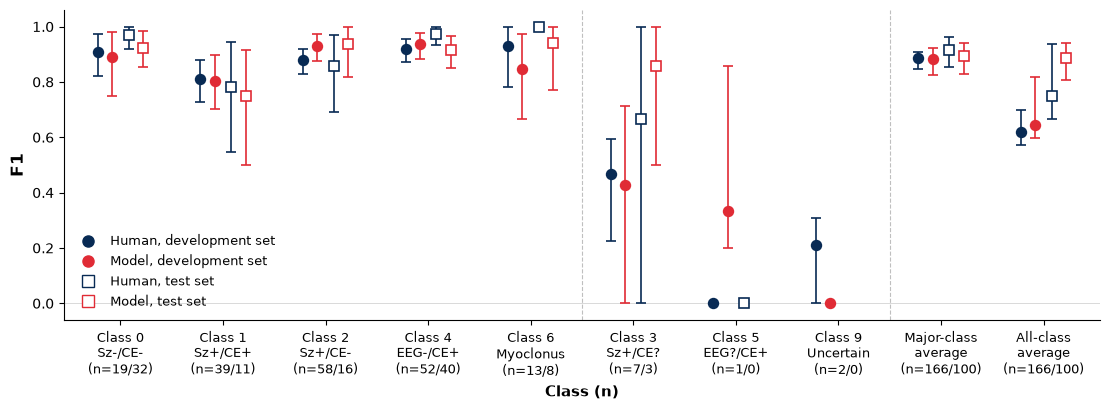

saved manuscript/fig2_f1.svg


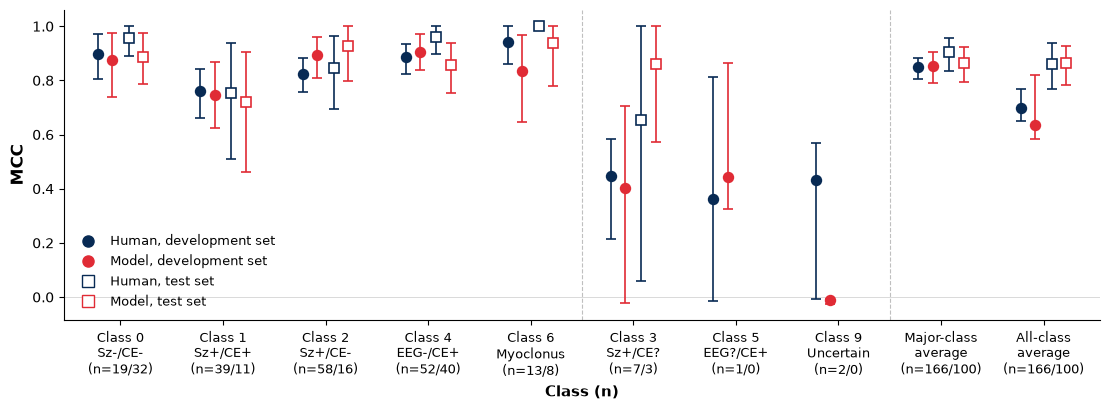

saved manuscript/fig2_mcc.svg


In [29]:
# Figure 2 val2: development vs validation cohort 2
from matplotlib.lines import Line2D

if 'scores_phys_bs' not in globals() or not isinstance(scores_phys, dict):
    scores_bundle = _load_scores_bootstrap()
    scores_phys = scores_bundle['scores_phys']
    scores_ds = scores_bundle['scores_ds']
    scores_phys_bs = scores_bundle['scores_phys_bs']
    scores_ds_bs = scores_bundle['scores_ds_bs']
if 'scores_val2_human_bs' not in globals() or scores_val2_human_bs is None or 'Y_cons2' not in globals():
    scores_bundle = _load_scores_bootstrap()
    if not scores_bundle.get('val2'):
        raise ValueError('scores_bootstrap.pkl is missing val2; re-run Calculate scores with SCORE_RECOMPUTE=True')
    _assign_val_globals('val2', scores_bundle['val2'])

res_ann_h = make_res_human(scores_phys, scores_phys_bs)
res_ann_m = make_res_model(scores_ds, scores_ds_bs, cons_index=-1)
res_val2_h = make_res_human(scores_val2_human, scores_val2_human_bs)
res_val2_m = make_res_model(scores_val2_model, scores_val2_model_bs, cons_index=0)

PHYS_COLOR = '#082A54'
MODEL_COLOR = '#E02B35'
tick_labels = figure2_tick_labels(y_true_bin, Y_cons2)
x = np.arange(len(tick_labels))
series = [
    dict(name='Human, development set', res=res_ann_h, color=PHYS_COLOR, marker='o', filled=True, offset=-0.22),
    dict(name='Model, development set', res=res_ann_m, color=MODEL_COLOR, marker='o', filled=True, offset=-0.08),
    dict(name='Human, test set', res=res_val2_h, color=PHYS_COLOR, marker='s', filled=False, offset=0.08),
    dict(name='Model, test set', res=res_val2_m, color=MODEL_COLOR, marker='s', filled=False, offset=0.22),
]
metrics = [
    ('f1', 'macro_f1', 'macro_f1_all', 'F1', 'fig2_f1.svg'),
    ('mcc', 'mcc_mean', 'mcc_mean_all', 'MCC', 'fig2_mcc.svg')
]


os.makedirs('manuscript', exist_ok=True)
for class_key, overall_maj, overall_all, ylab, fname in metrics:
    fig, ax = plt.subplots(figsize=(11.2, 4.2))
    ymin, ymax = np.inf, -np.inf
    for s in series:
        pts, yerr = figure2_pt_ci(s['res'], class_key, overall_maj, overall_all)
        mfc = s['color'] if s['filled'] else 'white'
        ax.errorbar(
            x + s['offset'], pts, yerr=yerr,
            fmt=s['marker'], color=s['color'], ecolor=s['color'],
            markerfacecolor=mfc, markeredgecolor=s['color'], markeredgewidth=1.2,
            markersize=7, capsize=3.5, capthick=1.1, elinewidth=1.2,
            linestyle='none', label=s['name'], zorder=3,
        )
        ymin = min(ymin, float(np.nanmin(pts - yerr[0])))
        ymax = max(ymax, float(np.nanmax(pts + yerr[1])))
    for _xv in figure2_divider_xpos():
        ax.axvline(_xv, color='0.75', linewidth=0.8, linestyle='--', zorder=1)
    ax.set_xticks(x)
    ax.set_xticklabels(tick_labels, fontsize=9)
    ax.set_xlim(-0.55, len(tick_labels) - 0.45)
    ax.set_xlabel('Class (n)', fontsize=11, fontweight='bold')
    ax.set_ylabel(ylab, fontsize=12, fontweight='bold')
    ax.tick_params(axis='y', labelsize=10)
    # if class_key == 'mcc':
    ax.set_ylim(min(-0.05, ymin - 0.06), max(1.02, ymax + 0.06))
    ax.axhline(0, color='0.85', linewidth=0.7, zorder=1)
    # else:
    #     ax.set_ylim(0, max(1.02, ymax + 0.06))
    legend_handles = [
        Line2D([0], [0], marker='o', color=PHYS_COLOR, markerfacecolor=PHYS_COLOR,
               linestyle='none', markersize=8, label='Human, development set'),
        Line2D([0], [0], marker='o', color=MODEL_COLOR, markerfacecolor=MODEL_COLOR,
               linestyle='none', markersize=8, label='Model, development set'),
        Line2D([0], [0], marker='s', color=PHYS_COLOR, markerfacecolor='white',
               markeredgecolor=PHYS_COLOR, linestyle='none', markersize=8,
               label='Human, test set'),
        Line2D([0], [0], marker='s', color=MODEL_COLOR, markerfacecolor='white',
               markeredgecolor=MODEL_COLOR, linestyle='none', markersize=8,
               label='Model, test set'),
    ]
    ax.legend(handles=legend_handles, frameon=False, fontsize=9, ncol=1, loc='lower left')
    sns.despine()
    plt.tight_layout()
    plt.show()
    out = f'manuscript/{fname}'
    fig.savefig(out)
    print(f'saved {out}')


### eFigure 2

- **eFigure 2A**: development set confusion matrices (`manuscript/eFig2A.svg`)
- **eFigure 2B**: test set confusion matrices (`manuscript/eFig2B.svg`)


eFigure 2a  development set


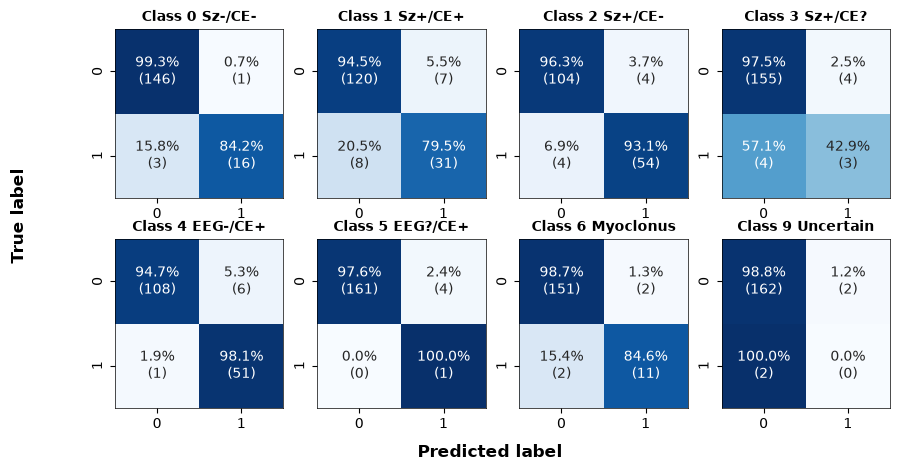

saved manuscript/eFig2A.svg
eFigure 2b  test set


C:\Users\haoershi\AppData\Local\Temp\ipykernel_16484\3045252107.py:33: RuntimeWarning: invalid value encountered in divide
  cm_percent = cm / row_sums * 100
C:\Users\haoershi\AppData\Local\Temp\ipykernel_16484\3045252107.py:33: RuntimeWarning: invalid value encountered in divide
  cm_percent = cm / row_sums * 100


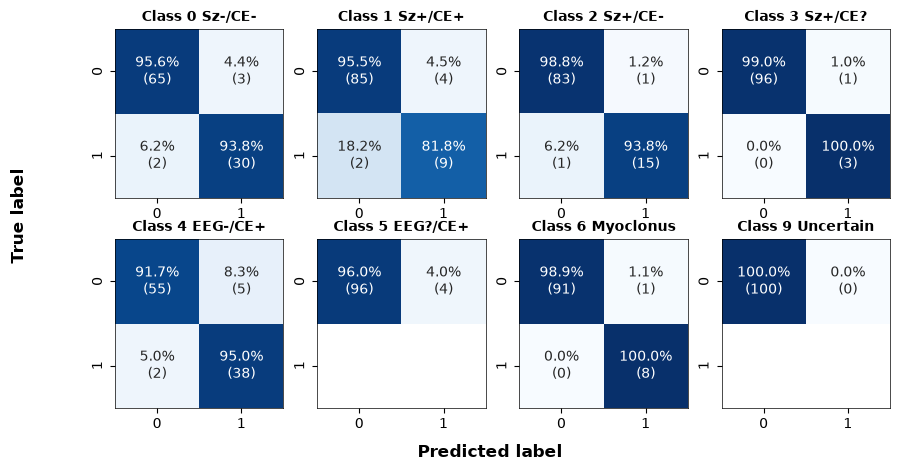

saved manuscript/eFig2B.svg


In [32]:
def _plot_class_cms(Y, Yhat, fname):
    Y = np.asarray(Y)
    Yhat = np.asarray(Yhat)
    fig, axs = plt.subplots(nrows=2, ncols=4, figsize=(10, 5))
    for i in range(Y.shape[1]):
        ax = axs[i // 4, i % 4]
        plot_confusion_matrix_with_counts(Y[:, i], Yhat[:, i], labels=[0, 1], ax=ax)
        ax.set_title(
            f'Class {class_inds[i]} {short_class_labels[class_inds[i]]}',
            fontweight='bold', fontsize=10,
        )
        ax.set_xlabel('')
        ax.set_ylabel('')
    fig.supylabel('True label', fontweight='bold', fontsize=12)
    fig.supxlabel('Predicted label', fontweight='bold', fontsize=12)
    plt.show()
    fig.savefig(fname)
    print('saved', fname)


def _bundle_cons_pred(bundle, key):
    b = bundle[key]
    Y = b['Y_cons']
    Yhat = b.get('Yhat', b.get('Yhat1'))
    if Yhat is None:
        raise ValueError(f'{key} pickle has no Yhat/Yhat1; re-run Calculate scores')
    return Y, Yhat


if 'Y_cons2' not in globals() or 'Yhat2' not in globals():
    scores_bundle = _load_scores_bootstrap()
    if not scores_bundle.get('val2'):
        raise ValueError('scores_bootstrap.pkl is missing val2; re-run Calculate scores with SCORE_RECOMPUTE=True')
    Y_cons2, Yhat2 = _bundle_cons_pred(scores_bundle, 'val2')

os.makedirs('manuscript', exist_ok=True)
print('eFigure 2a  development set')
_plot_class_cms(y_true_bin, full_pred, 'manuscript/eFig2A.svg')
print('eFigure 2b  test set')
_plot_class_cms(Y_cons2, Yhat2, 'manuscript/eFig2B.svg')


In [ ]:
# Pair-level full-data points (10 human pairs, 5 DS replicates) + consensus star
# CIs in the companion stats table come from cached bootstrap (median across pairs).
scores = ['f1_class', 'mcc_class', 'ac1_class']
group_palette = {'Human': '#082A54', 'DeepSeek': '#E02B35'}
all_data, consensus_data = [], []
for score in scores:
    for e, c in enumerate(classes):
        data = pd.DataFrame({
            'group': ['Human'] * n_pairs_annot + ['DeepSeek'] * n_ds_reps,
            'value': np.r_[scores_phys[score][:, e], scores_ds[score][:-1, e]],
        })
        data['class'] = c
        data['score'] = score
        all_data.append(data)
        consensus_data.append(pd.DataFrame({
            'group': ['Human', 'DeepSeek'],
            'value': [np.median(scores_phys[score][:, e]), scores_ds[score][-1, e]],
            'class': c,
            'score': score,
        }))
all_data = pd.concat(all_data, ignore_index=True)
consensus_data = pd.concat(consensus_data, ignore_index=True)

for score in scores:
    data = all_data[all_data['score'] == score]
    cons_data = consensus_data[consensus_data['score'] == score]
    fig, ax = plt.subplots(figsize=(7, 3.5))
    sns.boxplot(
        x='class', y='value', hue='group', data=data,
        dodge=True, notch=False, showcaps=True, showfliers=False,
        boxprops={'facecolor': 'white'}, gap=0.1, whis=1.5, width=0.8, ax=ax,
    )
    for patch in ax.patches:
        color = patch.get_facecolor()
        patch.set_facecolor((*color[:3], 0.5))
        patch.set_linewidth(1)
    sns.stripplot(
        x='class', y='value', hue='group', data=data, palette=group_palette,
        dodge=True, alpha=0.7, size=4, jitter=0.15, ax=ax,
    )
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    sns.stripplot(
        x='class', y='value', hue='group', data=cons_data, palette=group_palette,
        dodge=True, edgecolor='black', marker='*', linewidth=0.5, size=10, ax=ax, alpha=0.9,
    )
    x = np.arange(len(classes))
    ax.legend(by_label.values(), by_label.keys(), title='Group')
    ax.set_xticks(x)
    ax.set_xticklabels([class_tick_label(k) for k in short_class_labels], fontsize=10)
    ax.set_xlabel('Classes', fontsize=12, fontweight='bold')
    ax.set_ylabel(score_labels[score], fontsize=12, fontweight='bold')
    ax.tick_params(axis='y', labelsize=10)
    sns.despine()
    plt.tight_layout()
    plt.show()
    fig.savefig(f'manuscript/efig2B_{score}.svg')


In [ ]:
scores = ['macro_f1', 'micro_f1', 'mcc', 'ac1']
group_palette = {'Human': '#082A54', 'DeepSeek': '#E02B35'}
all_data, consensus_data = [], []
for score in scores:
    all_data.append(pd.DataFrame({
        'group': ['Human'] * n_pairs_annot + ['DeepSeek'] * n_ds_reps,
        'value': np.r_[np.asarray(scores_phys[score]).ravel(), np.asarray(scores_ds[score])[:-1]],
        'score': score,
    }))
    consensus_data.append(pd.DataFrame({
        'group': ['Human', 'DeepSeek'],
        'value': [float(np.median(scores_phys[score])), float(np.asarray(scores_ds[score])[-1])],
        'score': score,
    }))
all_data = pd.concat(all_data, ignore_index=True)
consensus_data = pd.concat(consensus_data, ignore_index=True)

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.boxplot(
    x='score', y='value', hue='group', data=all_data, color='white',
    dodge=True, notch=False, showcaps=True, showfliers=False,
    medianprops={'color': 'black', 'linewidth': 2},
    boxprops={'facecolor': 'white'}, gap=0.1, whis=1.5, width=0.8, ax=ax,
)
sns.stripplot(
    x='score', y='value', hue='group', data=all_data, palette=group_palette,
    dodge=True, alpha=0.7, size=5, jitter=0.15, ax=ax,
)
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
sns.stripplot(
    x='score', y='value', hue='group', data=consensus_data,
    dodge=True, color='red', edgecolor='black', marker='*', linewidth=0.5, size=10, ax=ax,
)
x = np.arange(len(scores))
ax.legend(by_label.values(), by_label.keys(), title='Group')
ax.set_xticks(x)
ax.set_xticklabels([score_labels[s] for s in scores], fontsize=12)
ax.set_xlabel('')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
sns.despine()
plt.tight_layout()
plt.show()
fig.savefig('manuscript/eFig3C.svg')


### eFigure 3

Each point in the box is one model run scored against human consensus. The star is the consensus model (`full_pred`), one value, and is not included in the box.

Saved as `manuscript/efig3A_{f1_class,mcc_class,ac1_class}.svg` and `manuscript/eFig3B.svg`.


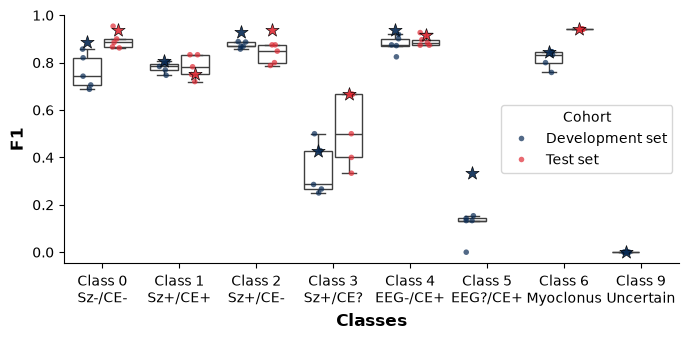

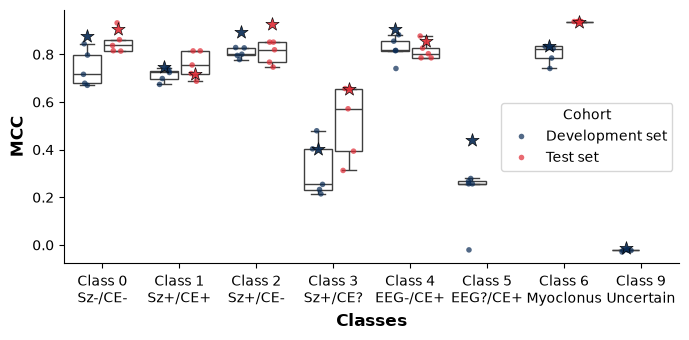

In [34]:
# eFigure 5B: per-class single runs (box) and consensus model (star)

def _score_val2_model_runs():
    """Each val2 model run vs human consensus; star is full_pred vs consensus.

    Built in the 'Build predictions from 5 runs' section (same layout as dev_data.pkl).
    """
    path = f'{DERIVED_DIR}/test_data.pkl'
    with open(path, 'rb') as f:
        _y_phys, _y_phys_bin, _y_true, Y_cons, _y_ds, y_runs, Y_star = pickle.load(f)
    Y_cons = np.asarray(Y_cons).astype(int)
    y_runs = [np.asarray(Y).astype(int) for Y in y_runs]
    Y_star = np.asarray(Y_star).astype(int)
    scores_runs = stack_pair_scores([(Y_cons, Y) for Y in y_runs])
    scores_star = stack_pair_scores([(Y_cons, Y_star)])
    print(f'test_data: n={Y_cons.shape[0]}  runs={len(y_runs)}  star=full_pred vs consensus')
    return scores_runs, scores_star

def _efig5_packs():
    g = globals()
    if 'scores_ds' not in g or not isinstance(g.get('scores_ds'), dict):
        bundle = _load_scores_bootstrap()
        g['scores_ds'] = bundle['scores_ds']
    if 'scores_val2_runs' not in g or g.get('scores_val2_runs') is None:
        runs, star = _score_val2_model_runs()
        g['scores_val2_runs'] = runs
        g['scores_val2_star'] = star
    return g['scores_ds'], g['scores_val2_runs'], g['scores_val2_star']

scores_ds, scores_val2_runs, scores_val2_star = _efig5_packs()
group_palette = {'Development set': '#082A54', 'Test set': '#E02B35'}
score_names = ['f1_class', 'mcc_class']
all_data, star_data = [], []
for score in score_names:
    ds = np.asarray(scores_ds[score], dtype=float)
    runs = np.asarray(scores_val2_runs[score], dtype=float)
    star = np.asarray(scores_val2_star[score], dtype=float)
    if runs.ndim == 1:
        runs = runs.reshape(1, -1)
    if star.ndim == 1:
        star = star.reshape(1, -1)
    for e, c in enumerate(classes):
        dev_runs = ds[:-1, e]
        val_runs = runs[:, e]
        data = pd.DataFrame({
            'group': ['Development set'] * len(dev_runs) + ['Test set'] * len(val_runs),
            'value': np.r_[dev_runs, val_runs],
        })
        data['class'] = c
        data['score'] = score
        all_data.append(data)
        star_data.append(pd.DataFrame({
            'group': ['Development set', 'Test set'],
            'value': [float(ds[-1, e]), float(star[0, e])],
            'class': c,
            'score': score,
        }))
all_data = pd.concat(all_data, ignore_index=True)
star_data = pd.concat(star_data, ignore_index=True)

os.makedirs('manuscript', exist_ok=True)
for score in score_names:
    data = all_data[all_data['score'] == score]
    cons_data = star_data[star_data['score'] == score]
    fig, ax = plt.subplots(figsize=(7, 3.5))
    sns.boxplot(
        x='class', y='value', hue='group', data=data,
        dodge=True, notch=False, showcaps=True, showfliers=False,
        boxprops={'facecolor': 'white'}, gap=0.1, whis=1.5, width=0.8, ax=ax,
    )
    for patch in ax.patches:
        color = patch.get_facecolor()
        patch.set_facecolor((*color[:3], 0.5))
        patch.set_linewidth(1)
    sns.stripplot(
        x='class', y='value', hue='group', data=data, palette=group_palette,
        dodge=True, alpha=0.7, size=4, jitter=0.15, ax=ax,
    )
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    sns.stripplot(
        x='class', y='value', hue='group', data=cons_data, palette=group_palette,
        dodge=True, edgecolor='black', marker='*', linewidth=0.5, size=10, ax=ax, alpha=0.9,
    )
    x = np.arange(len(classes))
    ax.legend(by_label.values(), by_label.keys(), title='Cohort')
    ax.set_xticks(x)
    ax.set_xticklabels([class_tick_label(k) for k in short_class_labels], fontsize=10)
    ax.set_xlabel('Classes', fontsize=12, fontweight='bold')
    ax.set_ylabel(score_labels[score], fontsize=12, fontweight='bold')
    ax.tick_params(axis='y', labelsize=10)
    sns.despine()
    plt.tight_layout()
    plt.show()
    fig.savefig(f'manuscript/efig3A_{score}.svg')


C:\Users\haoershi\AppData\Local\Temp\ipykernel_16484\3742493053.py:52: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:white'` for the same effect.

  sns.boxplot(


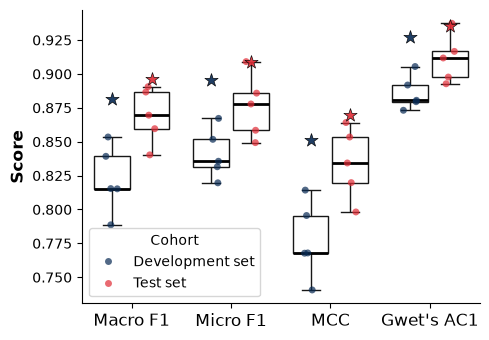

In [35]:
# eFigure 5C: overall single runs (box) and consensus model (star)

def _score_val2_model_runs():
    """Each val2 model run vs human consensus; star is full_pred vs consensus.

    Built in the 'Build predictions from 5 runs' section (same layout as dev_data.pkl).
    """
    path = f'{DERIVED_DIR}/test_data.pkl'
    with open(path, 'rb') as f:
        _y_phys, _y_phys_bin, _y_true, Y_cons, _y_ds, y_runs, Y_star = pickle.load(f)
    Y_cons = np.asarray(Y_cons).astype(int)
    y_runs = [np.asarray(Y).astype(int) for Y in y_runs]
    Y_star = np.asarray(Y_star).astype(int)
    scores_runs = stack_pair_scores([(Y_cons, Y) for Y in y_runs])
    scores_star = stack_pair_scores([(Y_cons, Y_star)])
    print(f'test_data: n={Y_cons.shape[0]}  runs={len(y_runs)}  star=full_pred vs consensus')
    return scores_runs, scores_star

def _efig5_packs():
    g = globals()
    if 'scores_ds' not in g or not isinstance(g.get('scores_ds'), dict):
        bundle = _load_scores_bootstrap()
        g['scores_ds'] = bundle['scores_ds']
    if 'scores_val2_runs' not in g or g.get('scores_val2_runs') is None:
        runs, star = _score_val2_model_runs()
        g['scores_val2_runs'] = runs
        g['scores_val2_star'] = star
    return g['scores_ds'], g['scores_val2_runs'], g['scores_val2_star']

scores_ds, scores_val2_runs, scores_val2_star = _efig5_packs()
group_palette = {'Development set': '#082A54', 'Test set': '#E02B35'}
score_names = ['macro_f1', 'micro_f1', 'mcc', 'ac1']
all_data, star_data = [], []
for score in score_names:
    ds = np.asarray(scores_ds[score], dtype=float).ravel()
    runs = np.asarray(scores_val2_runs[score], dtype=float).ravel()
    star = float(np.asarray(scores_val2_star[score], dtype=float).ravel()[0])
    all_data.append(pd.DataFrame({
        'group': ['Development set'] * (len(ds) - 1) + ['Test set'] * len(runs),
        'value': np.r_[ds[:-1], runs],
        'score': score,
    }))
    star_data.append(pd.DataFrame({
        'group': ['Development set', 'Test set'],
        'value': [float(ds[-1]), star],
        'score': score,
    }))
all_data = pd.concat(all_data, ignore_index=True)
star_data = pd.concat(star_data, ignore_index=True)

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.boxplot(
    x='score', y='value', hue='group', data=all_data, color='white',
    dodge=True, notch=False, showcaps=True, showfliers=False,
    medianprops={'color': 'black', 'linewidth': 2},
    boxprops={'facecolor': 'white'}, gap=0.1, whis=1.5, width=0.8, ax=ax,
)
sns.stripplot(
    x='score', y='value', hue='group', data=all_data, palette=group_palette,
    dodge=True, alpha=0.7, size=5, jitter=0.15, ax=ax,
)
handles, labels = ax.get_legend_handles_labels()
by_label = dict(zip(labels, handles))
sns.stripplot(
    x='score', y='value', hue='group', data=star_data, palette=group_palette,
    dodge=True, edgecolor='black', marker='*', linewidth=0.5, size=10, ax=ax, alpha=0.9,
)
x = np.arange(len(score_names))
ax.legend(by_label.values(), by_label.keys(), title='Cohort')
ax.set_xticks(x)
ax.set_xticklabels([score_labels[s] for s in score_names], fontsize=12)
ax.set_xlabel('')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
sns.despine()
plt.tight_layout()
plt.show()
fig.savefig('manuscript/eFig3B.svg')


### PPI: class frequency in the NLP cohort

Prediction-powered inference ([`ppi_py`](https://github.com/aangelopoulos/ppi_py); [Angelopoulos et al.](https://arxiv.org/abs/2301.09633)) combines gold-standard labels on the **random** 100 with model predictions on **all remaining NLP notes**.

The labeled 100 is the test set. Unlabeled `Yhat` is every other NLP note except the development set. Each class is a binary mean.

Reported for the analysis set (labeled + unlabeled NLP notes):
- **Labeled-only**: gold prevalence on the random 100
- **Model (unlabeled)**: raw model rate on unlabeled notes
- **Model (whole set)**: raw model rate on labeled + unlabeled
- **PPI (unlabeled)**: PPI++ estimate of unlabeled prevalence
- **Whole-set corrected**: \((n_L \bar Y + n_U \hat\theta_{\mathrm{PPI}}) / (n_L+n_U)\) - gold mean on labeled notes plus PPI on unlabeled. 95% CI combines the classical labeled SE and the PPI SE (independent samples).

**By recording type:** the same quantities inside each `TYPE` (LTM / AMB / ROUTINE).


Labeled random validation: n=100  (label col='label')
Unlabeled NLP notes (all other cases): n=3947
Target population size (labeled + unlabeled): 4047
Full NLP cohort: n=4213
model_pct: unlabeled model;  model_all_pct: raw model on labeled+unlabeled
ppi_pct: PPI on unlabeled;  whole_ppi_pct: (n_L * gold + n_U * PPI) / N


,Class,Label,n_labeled,n_unlabeled,labeled_pct,model_pct,model_all_pct,ppi_pct,ppi_ci_pct,whole_ppi_pct,whole_ppi_ci_pct
0,Class 0,Sz-/CE-,100,3947,32.0,22.80,23.05,21.80,"[17.23,26.37]",22.05,"[17.59,26.52]"
1,Class 1,Sz+/CE+,100,3947,11.0,12.24,12.26,10.48,"[6.16,14.79]",10.49,"[6.27,14.70]"
2,Class 2,Sz+/CE-,100,3947,16.0,16.85,16.83,16.74,"[13.80,19.67]",16.72,"[13.85,19.58]"
3,Class 3,Sz+/CE?,100,3947,3.0,5.04,5.02,3.61,"[1.76,5.46]",3.60,"[1.79,5.41]"
4,Class 4,EEG-/CE+,100,3947,40.0,47.94,47.81,44.01,"[38.90,49.12]",43.91,"[38.92,48.90]"
5,Class 5,EEG?/CE+,100,3947,0.0,3.55,3.56,0.00,"[0.00,0.00]",0.00,"[0.00,0.00]"
6,Class 6,Myoclonus,100,3947,8.0,8.08,8.10,7.13,"[5.08,9.17]",7.15,"[5.14,9.15]"
7,Class 9,Uncertain,100,3947,0.0,0.58,0.57,0.00,"[0.00,0.00]",0.00,"[0.00,0.00]"


saved manuscript/ppi_nlp_class_frequency.csv
Figure 3A  whole-set model bars + black PPI crosses (all classes)
saved manuscript/fig3a.svg


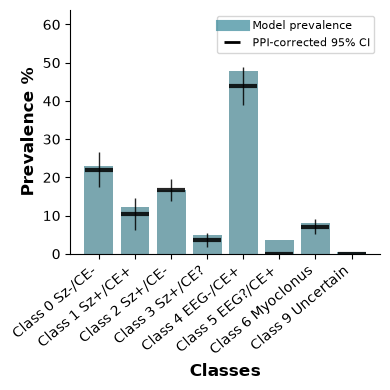

Labeled n by TYPE
TYPE
LTM        61
AMB        25
ROUTINE    14
Unlabeled n by TYPE
TYPE
LTM        2686
AMB         635
ROUTINE     626
LTM: labeled=61  unlabeled=2686
AMB: labeled=25  unlabeled=635
ROUTINE: labeled=14  unlabeled=626
PPI by recording type (NLP cohort)


,TYPE,Class,Label,n_labeled,n_unlabeled,labeled_pct,model_pct,model_all_pct,ppi_pct,ppi_ci_pct,whole_ppi_pct,whole_ppi_ci_pct
0,LTM,Class 0,Sz-/CE-,61,2686,26.23,19.32,19.51,17.91,"[10.69,25.13]",18.09,"[11.03,25.16]"
1,LTM,Class 1,Sz+/CE+,61,2686,16.39,15.79,15.84,14.72,"[8.11,21.33]",14.76,"[8.29,21.22]"
2,LTM,Class 2,Sz+/CE-,61,2686,22.95,21.74,21.73,23.36,"[19.83,26.88]",23.35,"[19.90,26.80]"
3,LTM,Class 3,Sz+/CE?,61,2686,3.28,6.03,6.01,3.88,"[1.12,6.64]",3.87,"[1.17,6.56]"
4,LTM,Class 4,EEG-/CE+,61,2686,36.07,42.67,42.63,37.28,"[29.36,45.19]",37.25,"[29.50,45.00]"
5,LTM,Class 5,EEG?/CE+,61,2686,0.00,3.87,3.90,0.00,"[0.00,0.00]",0.00,"[0.00,0.00]"
6,LTM,Class 6,Myoclonus,61,2686,11.48,10.65,10.70,9.01,"[5.62,12.40]",9.06,"[5.74,12.39]"
7,LTM,Class 9,Uncertain,61,2686,0.00,0.74,0.73,0.00,"[0.00,0.00]",0.00,"[0.00,0.00]"
8,AMB,Class 0,Sz-/CE-,25,635,32.00,17.64,18.18,17.64,"[14.67,20.60]",18.18,"[15.25,21.12]"
9,AMB,Class 1,Sz+/CE+,25,635,4.00,5.67,5.76,2.48,"[-3.41,8.37]",2.54,"[-3.14,8.21]"


saved manuscript/ppi_nlp_class_frequency_by_type.csv


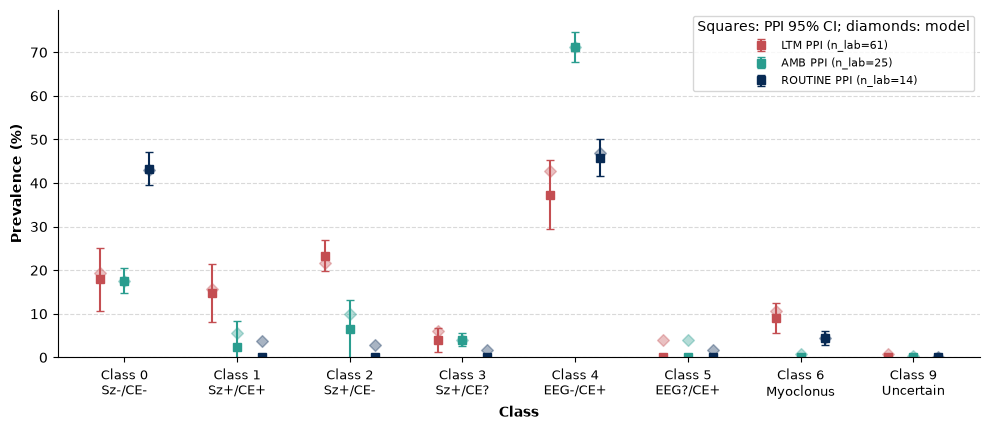

In [36]:
# Requires: pip install ppi-python
from ppi_py import ppi_mean_ci, ppi_mean_pointestimate
from ppi_py.baselines import classical_mean_ci
import seaborn as sns
from scipy.stats import norm

# Gold-standard labels for the random validation cohort.
# Edit this path if the annotated file lives elsewhere. Accepted label columns:
# class, true_class, label, Label, Label1, new_label, gold
PPI_LABEL_PATH = f'{RELEASE_DIR}/annot_test.csv'
SAMPLE_PATH = f'{RELEASE_DIR}/annot_test.csv'
PPI_ALPHA = 0.05  # 95% CI

if getattr(mlb, "classes_", None) is None:
    mlb.fit([[c] for c in class_inds])


LABEL_CANDIDATES = ['class', 'true_class', 'label', 'Label', 'Label1', 'new_label', 'gold']


def _parse_multilabel(x):
    if pd.isna(x):
        return []
    if isinstance(x, (int, np.integer, float, np.floating)) and not isinstance(x, bool):
        if isinstance(x, (float, np.floating)) and not np.isfinite(x):
            return []
        return [int(x)]
    return [int(i.strip()) for i in str(x).split(',') if str(i).strip() not in ('', 'nan', 'None')]


def _as_scalar_interval(lo, hi):
    lo = float(np.asarray(lo).reshape(-1)[0])
    hi = float(np.asarray(hi).reshape(-1)[0])
    return lo, hi


def _fmt_ci_pct(lo, hi):
    if not (np.isfinite(lo) and np.isfinite(hi)):
        return 'NA'
    return f'[{100 * lo:.2f},{100 * hi:.2f}]'


def _mix_whole(n_lab, n_unlab, a, b):
    n = n_lab + n_unlab
    if n <= 0:
        return np.nan
    if not np.isfinite(a) and not np.isfinite(b):
        return np.nan
    if not np.isfinite(a):
        return b if n_unlab else np.nan
    if not np.isfinite(b):
        return a if n_lab else np.nan
    return (n_lab * a + n_unlab * b) / n


def _ppi_table(Y, Yhat, Yhat_u, alpha=PPI_ALPHA):
    """Per-class labeled / model / PPI (unlabeled) / whole-set corrected prevalence."""
    Y = np.asarray(Y, dtype=float)
    Yhat = np.asarray(Yhat, dtype=float)
    Yhat_u = np.asarray(Yhat_u, dtype=float)
    if Yhat_u.ndim == 1:
        Yhat_u = Yhat_u.reshape(1, -1) if Yhat_u.size else np.zeros((0, Y.shape[1]))
    rows = []
    n_lab, n_unlab = int(Y.shape[0]), int(Yhat_u.shape[0])
    n_all = n_lab + n_unlab
    z = float(norm.ppf(1.0 - alpha / 2.0))
    for j, c in enumerate(class_inds):
        y = Y[:, j]
        yhat = Yhat[:, j]
        yhat_u = Yhat_u[:, j] if n_unlab else np.array([])
        labeled_prev = float(np.mean(y)) if n_lab else np.nan
        model_unlab = float(np.mean(yhat_u)) if n_unlab else np.nan
        model_lab = float(np.mean(yhat)) if n_lab else np.nan
        model_all = _mix_whole(n_lab, n_unlab, model_lab, model_unlab)
        try:
            class_lo, class_hi = _as_scalar_interval(*classical_mean_ci(y, alpha=alpha)) if n_lab else (np.nan, np.nan)
        except Exception:
            class_lo, class_hi = np.nan, np.nan
        theta = lo = hi = np.nan
        if n_lab >= 2 and n_unlab >= 1:
            try:
                theta = float(np.asarray(ppi_mean_pointestimate(y, yhat, yhat_u)).reshape(-1)[0])
                lo, hi = _as_scalar_interval(*ppi_mean_ci(y, yhat, yhat_u, alpha=alpha))
            except Exception as exc:
                print(f'  PPI failed class {c}: {exc}')
        if n_all <= 0:
            whole = np.nan
        elif not np.isfinite(theta):
            whole = labeled_prev if n_unlab == 0 else np.nan
        else:
            whole = _mix_whole(n_lab, n_unlab, labeled_prev, theta)
        se_lab = (class_hi - class_lo) / (2.0 * z) if np.isfinite(class_lo) and np.isfinite(class_hi) else np.nan
        se_ppi = (hi - lo) / (2.0 * z) if np.isfinite(lo) and np.isfinite(hi) else np.nan
        whole_lo = whole_hi = np.nan
        if n_all > 0 and np.isfinite(whole):
            w = n_lab / n_all
            var = 0.0
            if np.isfinite(se_lab):
                var += (w * se_lab) ** 2
            if np.isfinite(se_ppi):
                var += ((1.0 - w) * se_ppi) ** 2
            if var > 0:
                se = np.sqrt(var)
                whole_lo = whole - z * se
                whole_hi = whole + z * se
            else:
                whole_lo = _mix_whole(n_lab, n_unlab, class_lo if np.isfinite(class_lo) else labeled_prev, lo if np.isfinite(lo) else theta)
                whole_hi = _mix_whole(n_lab, n_unlab, class_hi if np.isfinite(class_hi) else labeled_prev, hi if np.isfinite(hi) else theta)
        rows.append({
            'class_id': int(c),
            'Class': class_name(c),
            'Label': short_class_labels.get(c, str(c)).replace('\n', ' '),
            'n_labeled': n_lab,
            'n_unlabeled': n_unlab,
            'labeled_prevalence': labeled_prev,
            'classical_lo': class_lo,
            'classical_hi': class_hi,
            'model_prevalence': model_unlab,
            'model_all_prevalence': model_all,
            'ppi_prevalence': theta,
            'ppi_lo': lo,
            'ppi_hi': hi,
            'whole_ppi_prevalence': whole,
            'whole_ppi_lo': whole_lo,
            'whole_ppi_hi': whole_hi,
        })
    out = pd.DataFrame(rows)
    out['labeled_pct'] = (100 * out['labeled_prevalence']).round(2)
    out['model_pct'] = (100 * out['model_prevalence']).round(2)
    out['model_all_pct'] = (100 * out['model_all_prevalence']).round(2)
    out['ppi_pct'] = (100 * out['ppi_prevalence']).round(2)
    out['ppi_ci_pct'] = [_fmt_ci_pct(a, b) for a, b in zip(out['ppi_lo'], out['ppi_hi'])]
    out['whole_ppi_pct'] = (100 * out['whole_ppi_prevalence']).round(2)
    out['whole_ppi_ci_pct'] = [_fmt_ci_pct(a, b) for a, b in zip(out['whole_ppi_lo'], out['whole_ppi_hi'])]
    return out


val_df = pd.read_csv(SAMPLE_PATH, dtype=dtype_dict)

val_df['ORDER_ID'] = val_df['ORDER_ID'].astype(str)

label_col = next((c for c in LABEL_CANDIDATES if c in val_df.columns), None)
if label_col is None:
    annot_rand = pd.read_csv(PPI_LABEL_PATH, dtype=dtype_dict)
    annot_rand['ORDER_ID'] = annot_rand['ORDER_ID'].astype(str)
    label_col = next((c for c in LABEL_CANDIDATES if c in annot_rand.columns), None)
    if label_col is None:
        raise ValueError(
            f'No label column found. Looked for {LABEL_CANDIDATES} in {SAMPLE_PATH} and {PPI_LABEL_PATH}. '
            f'Available annot columns: {list(annot_rand.columns)}'
        )
    val_df = val_df.merge(annot_rand[['ORDER_ID', label_col]].drop_duplicates('ORDER_ID'), on='ORDER_ID', how='left')

n_missing = val_df[label_col].isna().sum()
if n_missing:
    print(f'Dropping {n_missing} labeled-sample rows with missing {label_col}')
val_df = val_df.dropna(subset=[label_col]).drop_duplicates('ORDER_ID').reset_index(drop=True)

# Unlabeled = NLP notes that are not in the development set or the labeled test set.
labeled_ids = set(val_df['ORDER_ID'].astype(str))
used_note_ids = set(annot_df['ORDER_ID'].astype(str)).union(labeled_ids)

unlab_df = nlp_df.drop_duplicates('ORDER_ID').copy()
unlab_df['ORDER_ID'] = unlab_df['ORDER_ID'].astype(str)
unlab_df = unlab_df[~unlab_df['ORDER_ID'].isin(used_note_ids)].copy()

if 'pred_class' not in val_df.columns:
    val_df = val_df.merge(nlp_df[['ORDER_ID', 'pred_class']].drop_duplicates('ORDER_ID').assign(ORDER_ID=lambda d: d['ORDER_ID'].astype(str)), on='ORDER_ID', how='left')
val_df['pred_class'] = val_df['pred_class'].fillna('0')
unlab_df['pred_class'] = unlab_df['pred_class'].fillna('0')

Y = mlb.transform(val_df[label_col].map(_parse_multilabel).tolist()).astype(float)
Yhat = mlb.transform(val_df['pred_class'].map(_parse_multilabel).tolist()).astype(float)
Yhat_unlabeled = mlb.transform(unlab_df['pred_class'].map(_parse_multilabel).tolist()).astype(float)

print(f'Labeled random validation: n={len(val_df)}  (label col={label_col!r})')
print(f'Unlabeled NLP notes (all other cases): n={len(unlab_df)}')
print(f'Target population size (labeled + unlabeled): {len(val_df) + len(unlab_df)}')
print(f'Full NLP cohort: n={nlp_df["ORDER_ID"].nunique()}')

ppi_freq = _ppi_table(Y, Yhat, Yhat_unlabeled)
display_cols = ['Class', 'Label', 'n_labeled', 'n_unlabeled', 'labeled_pct', 'model_pct', 'model_all_pct', 'ppi_pct', 'ppi_ci_pct', 'whole_ppi_pct', 'whole_ppi_ci_pct']
print('model_pct: unlabeled model;  model_all_pct: raw model on labeled+unlabeled')
print('ppi_pct: PPI on unlabeled;  whole_ppi_pct: (n_L * gold + n_U * PPI) / N')
display(ppi_freq[display_cols])
ppi_freq.to_csv('manuscript/ppi_nlp_class_frequency.csv', index=False)
print('saved manuscript/ppi_nlp_class_frequency.csv')

# Figure 3A: same style as Figure 3B — bars (model) + cross PPI 95% CI
FIG3A_BAR = '#368899'
FIG3A_PPI = 'black'


def _fig3a_overlay_ppi(ax, plot_df, class_order):
    xmap = {cls: i for i, cls in enumerate(class_order)}
    xs, ys, e0, e1 = [], [], [], []
    for _, row in plot_df.iterrows():
        if row['Class'] not in xmap or not np.isfinite(row['ppi']):
            continue
        y = float(row['ppi'])
        lo = float(row['ppi_lo']) if np.isfinite(row['ppi_lo']) else y
        hi = float(row['ppi_hi']) if np.isfinite(row['ppi_hi']) else y
        xs.append(xmap[row['Class']])
        ys.append(y)
        e0.append(max(y - lo, 0.0))
        e1.append(max(hi - y, 0.0))
    if xs:
        ax.errorbar(
            xs, ys, yerr=[e0, e1], fmt='_', color=FIG3A_PPI,
            capsize=0, markersize=20, zorder=4, markeredgecolor=FIG3A_PPI,
            markeredgewidth=3, alpha=0.85,linewidth=1,
        )


def _draw_fig3a_overall(df3a):
    plot_df = pd.DataFrame({
        'Class': [f'Class{c}' for c in class_inds],
        'value': 100 * df3a['model_all_prevalence'].to_numpy(dtype=float),
        'ppi': 100 * df3a['whole_ppi_prevalence'].to_numpy(dtype=float),
        'ppi_lo': 100 * df3a['whole_ppi_lo'].to_numpy(dtype=float),
        'ppi_hi': 100 * df3a['whole_ppi_hi'].to_numpy(dtype=float),
    })
    order = [f'Class{c}' for c in class_inds]
    fig, ax = plt.subplots(figsize=(4, 4))
    sns.barplot(
        x='Class', y='value', order=order, color=FIG3A_BAR, alpha=0.7,
        data=plot_df, ax=ax,
    )
    _fig3a_overlay_ppi(ax, plot_df, order)
    hi_cols = ['value', 'ppi', 'ppi_hi']
    ymax = float(np.nanmax(plot_df[hi_cols].to_numpy(dtype=float))) if len(plot_df) else 1.0
    if not np.isfinite(ymax):
        ymax = 1.0
    ax.set_ylim(0, ymax * 1.1+10)
    ax.set_ylabel('Prevalence %', fontweight='bold', fontsize=12)
    ax.set_xticks(range(len(class_inds)))
    ax.set_xticklabels([class_tick_label(c, sep=' ') for c in class_inds], rotation=40, ha='right')
    ax.set_xlabel('Classes', fontweight='bold', fontsize=12)
    from matplotlib.lines import Line2D
    legend_handles = [
        Line2D([0], [0], color=FIG3A_BAR, lw=8, alpha=0.7, label='Model prevalence'),
        Line2D([0], [0], color=FIG3A_PPI, marker='_', linestyle='None', markersize=12,
               markeredgewidth=2, label='PPI-corrected 95% CI'),
    ]
    ax.legend(handles=legend_handles, frameon=True, fontsize=8, loc='upper right')
    sns.despine()
    fig.tight_layout()
    return fig


df3a = ppi_freq.set_index('class_id').reindex(class_inds)
fig = _draw_fig3a_overall(df3a)
print('Figure 3A  whole-set model bars + black PPI crosses (all classes)')
fig.savefig('manuscript/fig3a.svg', dpi=300, bbox_inches='tight')
print('saved manuscript/fig3a.svg')
plt.show()

# --- PPI by recording type (NLP cohort only) ---
PPI_TYPES = ['LTM', 'AMB', 'ROUTINE']
type_src = seizure_orders[['ORDER_ID', 'TYPE']].drop_duplicates('ORDER_ID').copy()
type_src['ORDER_ID'] = type_src['ORDER_ID'].astype(str)
if 'TYPE' not in val_df.columns:
    val_df = val_df.merge(type_src, on='ORDER_ID', how='left')
else:
    miss = val_df['TYPE'].isna()
    if miss.any():
        val_df.loc[miss, 'TYPE'] = val_df.loc[miss, 'ORDER_ID'].map(type_src.set_index('ORDER_ID')['TYPE'])
if 'TYPE' not in unlab_df.columns:
    unlab_df = unlab_df.merge(type_src, on='ORDER_ID', how='left')
else:
    miss = unlab_df['TYPE'].isna()
    if miss.any():
        unlab_df.loc[miss, 'TYPE'] = unlab_df.loc[miss, 'ORDER_ID'].map(type_src.set_index('ORDER_ID')['TYPE'])

print('Labeled n by TYPE')
print(val_df['TYPE'].value_counts(dropna=False).to_string())
print('Unlabeled n by TYPE')
print(unlab_df['TYPE'].value_counts(dropna=False).to_string())

vtype = val_df['TYPE'].astype(str)
utype = unlab_df['TYPE'].astype(str)
ppi_by_type_parts = []
for tname in PPI_TYPES:
    vm = vtype.eq(tname).to_numpy()
    um = utype.eq(tname).to_numpy()
    print(f'{tname}: labeled={int(vm.sum())}  unlabeled={int(um.sum())}')
    if vm.sum() < 2:
        print(f'  skip PPI ({tname}): need >=2 labeled notes')
        continue
    Yu = Yhat_unlabeled[um] if um.any() else np.zeros((0, Y.shape[1]))
    tab = _ppi_table(Y[vm], Yhat[vm], Yu)
    tab.insert(0, 'TYPE', tname)
    ppi_by_type_parts.append(tab)

ppi_by_type = pd.concat(ppi_by_type_parts, ignore_index=True) if ppi_by_type_parts else pd.DataFrame()
display_cols_t = ['TYPE'] + display_cols
print('PPI by recording type (NLP cohort)')
if len(ppi_by_type):
    display(ppi_by_type[display_cols_t])
    ppi_by_type.to_csv('manuscript/ppi_nlp_class_frequency_by_type.csv', index=False)
    print('saved manuscript/ppi_nlp_class_frequency_by_type.csv')
else:
    print('no TYPE had enough labeled notes for PPI')


### eTable 5 NLP cohort prevalence (model vs PPI)

Raw model prevalence is the mean predicted label on the **full NLP cohort** (n=4213). PPI-corrected prevalence is the whole-set mix \((n_L \bar Y + n_U \hat\theta_{\mathrm{PPI}}) / N\): gold labels on the random 100 plus PPI++ on every other NLP note (including previously annotated / validation-cohort-1 notes as unlabeled). **Any seizure** = OR of classes 1–3; **any event** = OR of classes 4–5.

PPI is reported as percent with 95% CI. It is **NA** when that stratum has fewer than 2 labeled notes or **no labeled positive** for that outcome (rectifier not identified).


In [37]:
# eTable 5 — requires the PPI cell (val_df, label_col, mlb, _mix_whole, _as_scalar_interval)
if 'val_df' not in globals() or 'label_col' not in globals():
    raise RuntimeError('Run the PPI cell first (defines val_df, label_col, mlb).')

ET5_TYPES = ['LTM', 'AMB', 'ROUTINE']


def _ppi_one(y, yhat, yhat_u, yhat_full=None, alpha=PPI_ALPHA):
    """Labeled gold / unlabeled PPI / whole-set mix. Raw model uses yhat_full if given."""
    y = np.asarray(y, dtype=float).ravel()
    yhat = np.asarray(yhat, dtype=float).ravel()
    yhat_u = np.asarray(yhat_u, dtype=float).ravel()
    n_lab, n_unlab = int(y.size), int(yhat_u.size)
    n_all = n_lab + n_unlab
    z = float(norm.ppf(1.0 - alpha / 2.0))
    labeled_prev = float(np.mean(y)) if n_lab else np.nan
    model_lab = float(np.mean(yhat)) if n_lab else np.nan
    model_unlab = float(np.mean(yhat_u)) if n_unlab else np.nan
    if yhat_full is not None and np.asarray(yhat_full).size:
        model_raw = float(np.mean(np.asarray(yhat_full, dtype=float)))
    else:
        model_raw = _mix_whole(n_lab, n_unlab, model_lab, model_unlab)
    n_pos = int(np.nansum(y)) if n_lab else 0
    try:
        class_lo, class_hi = _as_scalar_interval(*classical_mean_ci(y, alpha=alpha)) if n_lab else (np.nan, np.nan)
    except Exception:
        class_lo, class_hi = np.nan, np.nan
    theta = lo = hi = np.nan
    skip_reason = None
    if n_lab < 2:
        skip_reason = 'n_labeled<2'
    elif n_pos == 0:
        skip_reason = 'no labeled positive'
    elif n_unlab < 1:
        skip_reason = 'no unlabeled'
    else:
        try:
            theta = float(np.asarray(ppi_mean_pointestimate(y, yhat, yhat_u)).reshape(-1)[0])
            lo, hi = _as_scalar_interval(*ppi_mean_ci(y, yhat, yhat_u, alpha=alpha))
        except Exception as exc:
            skip_reason = f'PPI failed: {exc}'
            theta = lo = hi = np.nan
    if n_all <= 0:
        whole = np.nan
    elif not np.isfinite(theta):
        whole = np.nan
    else:
        whole = _mix_whole(n_lab, n_unlab, labeled_prev, theta)
    se_lab = (class_hi - class_lo) / (2.0 * z) if np.isfinite(class_lo) and np.isfinite(class_hi) else np.nan
    se_ppi = (hi - lo) / (2.0 * z) if np.isfinite(lo) and np.isfinite(hi) else np.nan
    whole_lo = whole_hi = np.nan
    if n_all > 0 and np.isfinite(whole):
        w = n_lab / n_all
        var = 0.0
        if np.isfinite(se_lab):
            var += (w * se_lab) ** 2
        if np.isfinite(se_ppi):
            var += ((1.0 - w) * se_ppi) ** 2
        if var > 0:
            se = np.sqrt(var)
            whole_lo = whole - z * se
            whole_hi = whole + z * se
        else:
            whole_lo = _mix_whole(n_lab, n_unlab, class_lo if np.isfinite(class_lo) else labeled_prev, lo if np.isfinite(lo) else theta)
            whole_hi = _mix_whole(n_lab, n_unlab, class_hi if np.isfinite(class_hi) else labeled_prev, hi if np.isfinite(hi) else theta)
    return {
        'n_labeled': n_lab,
        'n_unlabeled': n_unlab,
        'n_pos_labeled': n_pos,
        'model_raw': model_raw,
        'ppi_unlabeled': theta,
        'ppi_lo': lo,
        'ppi_hi': hi,
        'whole_ppi': whole,
        'whole_ppi_lo': whole_lo,
        'whole_ppi_hi': whole_hi,
        'skip_reason': skip_reason,
    }


def _fmt_prev_pct(pt, lo=np.nan, hi=np.nan, with_ci=False):
    if not np.isfinite(pt):
        return 'NA'
    if not with_ci:
        return f'{100 * pt:.2f}'
    if not (np.isfinite(lo) and np.isfinite(hi)):
        return f'{100 * pt:.2f}'
    return f'{100 * pt:.2f} [{100 * lo:.2f},{100 * hi:.2f}]'


def _outcome_vec(M, spec):
    M = np.asarray(M, dtype=float)
    if spec == 'seizure':
        return _or_bin(M, SEIZURE_COLS).astype(float)
    if spec == 'event':
        return _or_bin(M, EVENT_COLS).astype(float)
    return M[:, int(spec)].astype(float)


nlp_all = nlp_df.drop_duplicates('ORDER_ID').copy()
nlp_all['ORDER_ID'] = nlp_all['ORDER_ID'].astype(str)
nlp_all['pred_class'] = nlp_all['pred_class'].fillna('0')
type_src = seizure_orders[['ORDER_ID', 'TYPE']].drop_duplicates('ORDER_ID').copy()
type_src['ORDER_ID'] = type_src['ORDER_ID'].astype(str)
if 'TYPE' in nlp_all.columns:
    nlp_all = nlp_all.drop(columns=['TYPE'])
nlp_all = nlp_all.merge(type_src, on='ORDER_ID', how='left')

labeled_ids = set(val_df['ORDER_ID'].astype(str))
lab_mask = nlp_all['ORDER_ID'].isin(labeled_ids).to_numpy()
unlab_mask = ~lab_mask
Yhat_full = mlb.transform(nlp_all['pred_class'].map(_parse_multilabel).tolist()).astype(float)
Y_lab = mlb.transform(val_df[label_col].map(_parse_multilabel).tolist()).astype(float)
Yhat_lab = mlb.transform(val_df['pred_class'].fillna('0').map(_parse_multilabel).tolist()).astype(float)
Yhat_u_full = Yhat_full[unlab_mask]

vtype = val_df['TYPE'].astype(str) if 'TYPE' in val_df.columns else pd.Series([''] * len(val_df))
if 'TYPE' not in val_df.columns or vtype.eq('nan').all() or vtype.eq('').all():
    val_map = type_src.set_index('ORDER_ID')['TYPE']
    vtype = val_df['ORDER_ID'].astype(str).map(val_map).astype(str)
ntype = nlp_all['TYPE'].astype(str)

n_nlp = int(nlp_all['ORDER_ID'].nunique())
n_by_type = {t: int(ntype.eq(t).sum()) for t in ET5_TYPES}
print(f'eTable 5  full NLP cohort n={n_nlp}  labeled={len(val_df)}  unlabeled={int(unlab_mask.sum())}')
print('NLP n by TYPE', n_by_type)
print('Labeled n by TYPE', {t: int(vtype.eq(t).sum()) for t in ET5_TYPES})

outcomes = [(class_name(c), short_class_labels.get(c, str(c)).replace('\n', ' '), j) for j, c in enumerate(class_inds)]
outcomes += [
    ('Seizure (1–3)', 'Any class 1–3', 'seizure'),
    ('Event (4–5)', 'Any class 4–5', 'event'),
]

strata = [('Overall', np.ones(len(val_df), dtype=bool), np.ones(len(nlp_all), dtype=bool))]
for tname in ET5_TYPES:
    strata.append((tname, vtype.eq(tname).to_numpy(), ntype.eq(tname).to_numpy()))

et5_numeric_rows = []
display_rows = []
skip_notes = []
for class_lab, short_lab, spec in outcomes:
    row_disp = {'Class': class_lab, 'Label': short_lab}
    row_num = {'Class': class_lab, 'Label': short_lab}
    for sname, lab_m, full_m in strata:
        y = _outcome_vec(Y_lab[lab_m], spec) if lab_m.any() else np.array([])
        yhat = _outcome_vec(Yhat_lab[lab_m], spec) if lab_m.any() else np.array([])
        yhat_u = _outcome_vec(Yhat_full[unlab_mask & full_m], spec)
        yhat_f = _outcome_vec(Yhat_full[full_m], spec)
        st = _ppi_one(y, yhat, yhat_u, yhat_full=yhat_f)
        prefix = 'Overall' if sname == 'Overall' else sname
        row_num[f'{prefix}_n_nlp'] = int(full_m.sum())
        row_num[f'{prefix}_n_labeled'] = st['n_labeled']
        row_num[f'{prefix}_n_pos_labeled'] = st['n_pos_labeled']
        row_num[f'{prefix}_model'] = st['model_raw']
        row_num[f'{prefix}_ppi'] = st['whole_ppi']
        row_num[f'{prefix}_ppi_lo'] = st['whole_ppi_lo']
        row_num[f'{prefix}_ppi_hi'] = st['whole_ppi_hi']
        if st['skip_reason']:
            skip_notes.append(f'{class_lab} / {sname}: {st["skip_reason"]} (n_lab={st["n_labeled"]}, n_pos={st["n_pos_labeled"]})')
        raw_col = f'Overall model % (n={n_nlp})' if sname == 'Overall' else f'{sname} model % (n={n_by_type[sname]})'
        ppi_col = 'Overall PPI % (95% CI)' if sname == 'Overall' else f'{sname} PPI % (95% CI)'
        row_disp[raw_col] = _fmt_prev_pct(st['model_raw'])
        row_disp[ppi_col] = _fmt_prev_pct(st['whole_ppi'], st['whole_ppi_lo'], st['whole_ppi_hi'], with_ci=True)
    display_rows.append(row_disp)
    et5_numeric_rows.append(row_num)

etable5 = pd.DataFrame(display_rows)
etable5_full = pd.DataFrame(et5_numeric_rows)
print('eTable 5  NLP cohort model vs PPI prevalence')
display(etable5)
if skip_notes:
    print('PPI set to NA:')
    for line in skip_notes:
        print(' ', line)
etable5.to_csv('manuscript/etable5.csv', index=False)
etable5_full.to_csv('manuscript/etable5_full.csv', index=False)
print('saved manuscript/etable5.csv and manuscript/etable5_full.csv')


eTable 5  full NLP cohort n=4213  labeled=100  unlabeled=4113
NLP n by TYPE {'LTM': 2876, 'AMB': 686, 'ROUTINE': 651}
Labeled n by TYPE {'LTM': 61, 'AMB': 25, 'ROUTINE': 14}
eTable 5  NLP cohort model vs PPI prevalence


,Class,Label,Overall model % (n=4213),Overall PPI % (95% CI),LTM model % (n=2876),LTM PPI % (95% CI),AMB model % (n=686),AMB PPI % (95% CI),ROUTINE model % (n=651),ROUTINE PPI % (95% CI)
0,Class 0,Sz-/CE-,22.57,"21.57 [17.12,26.03]",19.12,"17.58 [10.45,24.70]",17.93,"17.93 [15.07,20.79]",42.70,"43.02 [39.27,46.78]"
1,Class 1,Sz+/CE+,12.65,"10.77 [6.55,14.98]",16.13,"15.00 [8.54,21.46]",6.56,"3.17 [-2.34,8.68]",3.69,NA
2,Class 2,Sz+/CE-,17.59,"17.33 [14.44,20.22]",22.57,"24.10 [20.64,27.57]",10.79,"7.15 [0.75,13.55]",2.76,NA
3,Class 3,Sz+/CE?,5.10,"3.64 [1.82,5.46]",6.02,"3.87 [1.17,6.57]",4.23,"4.21 [2.68,5.73]",2.00,NA
4,Class 4,EEG-/CE+,47.26,"43.47 [38.48,48.46]",41.86,"36.70 [28.95,44.45]",70.12,"70.12 [66.70,73.53]",47.00,"45.88 [41.65,50.12]"
5,Class 5,EEG?/CE+,3.58,NA,3.93,NA,3.94,NA,1.69,NA
6,Class 6,Myoclonus,8.17,"7.21 [5.22,9.20]",10.71,"9.07 [5.75,12.39]",0.73,NA,4.76,"4.76 [3.13,6.40]"
7,Class 9,Uncertain,0.55,NA,0.70,NA,0.29,NA,0.15,NA
8,Seizure (1–3),Any class 1–3,29.50,"27.03 [23.16,30.89]",37.48,"35.63 [30.15,41.11]",17.06,"13.44 [6.17,20.70]",7.37,NA
9,Event (4–5),Any class 4–5,49.35,"42.56 [36.85,48.28]",44.30,"36.09 [27.64,44.54]",71.28,"67.28 [59.15,75.42]",48.54,"47.23 [42.97,51.50]"


PPI set to NA:
  Class 1 / ROUTINE: no labeled positive (n_lab=14, n_pos=0)
  Class 2 / ROUTINE: no labeled positive (n_lab=14, n_pos=0)
  Class 3 / ROUTINE: no labeled positive (n_lab=14, n_pos=0)
  Class 5 / Overall: no labeled positive (n_lab=100, n_pos=0)
  Class 5 / LTM: no labeled positive (n_lab=61, n_pos=0)
  Class 5 / AMB: no labeled positive (n_lab=25, n_pos=0)
  Class 5 / ROUTINE: no labeled positive (n_lab=14, n_pos=0)
  Class 6 / AMB: no labeled positive (n_lab=25, n_pos=0)
  Class 9 / Overall: no labeled positive (n_lab=100, n_pos=0)
  Class 9 / LTM: no labeled positive (n_lab=61, n_pos=0)
  Class 9 / AMB: no labeled positive (n_lab=25, n_pos=0)
  Class 9 / ROUTINE: no labeled positive (n_lab=14, n_pos=0)
  Seizure (1–3) / ROUTINE: no labeled positive (n_lab=14, n_pos=0)
saved manuscript/etable5.csv and manuscript/etable5_full.csv


### eTable 6 Full-cohort prevalence (n=16976)

Same quantities as eTable 5, rebased to **all EEG orders**. Notes without an NLP report are treated as **class 0** (no seizure / event). For classes 1–9, any seizure, and any event the numerator is unchanged and the denominator is the full-cohort *n*; class 0 adds those non-NLP notes as positives.


In [ ]:
# eTable 5b — rebase eTable 5 NLP prevalences onto all EEG orders (non-NLP = class 0)
if 'etable5_full' not in globals():
    raise RuntimeError('Run eTable 5 first (defines etable5_full).')

orders_all = seizure_orders.drop_duplicates('ORDER_ID').copy()
orders_all['ORDER_ID'] = orders_all['ORDER_ID'].astype(str)
n_full = int(len(orders_all))
n_full_by_type = {t: int((orders_all['TYPE'].astype(str) == t).sum()) for t in ET5_TYPES}
print(f'eTable 5b  full EEG cohort n={n_full}')
print('Orders n by TYPE', n_full_by_type)
print('NLP n by TYPE', {t: int(etable5_full.iloc[0][f"{t}_n_nlp"]) for t in ET5_TYPES})


def _rebase_to_orders(p, lo, hi, n_nlp, n_ord, class0=False):
    n_nlp = float(n_nlp)
    n_ord = float(n_ord)
    if n_ord <= 0:
        return np.nan, np.nan, np.nan
    n_other = max(n_ord - n_nlp, 0.0)
    w = n_nlp / n_ord
    w_other = n_other / n_ord

    def _one(x, add_other):
        if x is None or (isinstance(x, float) and not np.isfinite(x)):
            return np.nan
        x = float(x)
        if not np.isfinite(x):
            return np.nan
        return w * x + (w_other if add_other else 0.0)

    return _one(p, class0), _one(lo, class0), _one(hi, class0)


disp_rows = []
num_rows = []
for _, r in etable5_full.iterrows():
    class0 = str(r['Class']) == class_name(0)
    d = {'Class': r['Class'], 'Label': r['Label']}
    n = {'Class': r['Class'], 'Label': r['Label'], 'class0_fill': bool(class0)}
    for sname in ['Overall'] + ET5_TYPES:
        n_nlp_s = float(r[f'{sname}_n_nlp'])
        n_ord_s = float(n_full if sname == 'Overall' else n_full_by_type[sname])
        raw, _, _ = _rebase_to_orders(r[f'{sname}_model'], np.nan, np.nan, n_nlp_s, n_ord_s, class0=class0)
        ppi, lo, hi = _rebase_to_orders(
            r[f'{sname}_ppi'], r[f'{sname}_ppi_lo'], r[f'{sname}_ppi_hi'],
            n_nlp_s, n_ord_s, class0=class0,
        )
        n[f'{sname}_n_orders'] = int(n_ord_s)
        n[f'{sname}_n_nlp'] = int(n_nlp_s)
        n[f'{sname}_model'] = raw
        n[f'{sname}_ppi'] = ppi
        n[f'{sname}_ppi_lo'] = lo
        n[f'{sname}_ppi_hi'] = hi
        raw_col = f'Overall model % (n={n_full})' if sname == 'Overall' else f'{sname} model % (n={n_full_by_type[sname]})'
        ppi_col = 'Overall PPI % (95% CI)' if sname == 'Overall' else f'{sname} PPI % (95% CI)'
        d[raw_col] = _fmt_prev_pct(raw)
        d[ppi_col] = _fmt_prev_pct(ppi, lo, hi, with_ci=True)
    disp_rows.append(d)
    num_rows.append(n)

etable5b = pd.DataFrame(disp_rows)
etable5b_full = pd.DataFrame(num_rows)
print('eTable 6  full EEG cohort model vs PPI prevalence (non-NLP = class 0)')
display(etable5b)
etable5b.to_csv('manuscript/etable6.csv', index=False)
etable5b_full.to_csv('manuscript/etable6_full.csv', index=False)
print('saved manuscript/etable6.csv and manuscript/etable6_full.csv')


eTable 5b  full EEG cohort n=16976
Orders n by TYPE {'LTM': 8902, 'AMB': 1352, 'ROUTINE': 6722}
NLP n by TYPE {'LTM': 2876, 'AMB': 686, 'ROUTINE': 651}
eTable 5b  full EEG cohort model vs PPI prevalence (non-NLP = class 0)


,Class,Label,Overall model % (n=16976),Overall PPI % (95% CI),LTM model % (n=8902),LTM PPI % (95% CI),AMB model % (n=1352),AMB PPI % (95% CI),ROUTINE model % (n=6722),ROUTINE PPI % (95% CI)
0,Class 0,Sz-/CE-,80.78,"80.54 [79.43,81.64]",73.87,"73.37 [71.07,75.67]",58.36,"58.36 [56.91,59.81]",94.45,"94.48 [94.12,94.85]"
1,Class 1,Sz+/CE+,3.14,"2.67 [1.63,3.72]",5.21,"4.85 [2.76,6.93]",3.33,"1.61 [-1.19,4.40]",0.36,NA
2,Class 2,Sz+/CE-,4.36,"4.30 [3.58,5.02]",7.29,"7.79 [6.67,8.91]",5.47,"3.63 [0.38,6.87]",0.27,NA
3,Class 3,Sz+/CE?,1.27,"0.90 [0.45,1.35]",1.94,"1.25 [0.38,2.12]",2.14,"2.13 [1.36,2.91]",0.19,NA
4,Class 4,EEG-/CE+,11.73,"10.79 [9.55,12.03]",13.53,"11.86 [9.35,14.36]",35.58,"35.58 [33.84,37.31]",4.55,"4.44 [4.03,4.85]"
5,Class 5,EEG?/CE+,0.89,NA,1.27,NA,2.00,NA,0.16,NA
6,Class 6,Myoclonus,2.03,"1.79 [1.29,2.28]",3.46,"2.93 [1.86,4.00]",0.37,NA,0.46,"0.46 [0.30,0.62]"
7,Class 9,Uncertain,0.14,NA,0.22,NA,0.15,NA,0.01,NA
8,Seizure (1–3),Any class 1–3,7.32,"6.71 [5.75,7.67]",12.11,"11.51 [9.74,13.28]",8.65,"6.82 [3.13,10.51]",0.71,NA
9,Event (4–5),Any class 4–5,12.25,"10.56 [9.14,11.98]",14.31,"11.66 [8.93,14.39]",36.17,"34.14 [30.01,38.27]",4.70,"4.57 [4.16,4.99]"


saved manuscript/etable6.csv and manuscript/etable6_full.csv


### Figure 3 Class frequency (NLP overall and by recording type)

**Figure 3A**: labeled + unlabeled NLP notes — whole-set model prevalence (bars) with PPI-corrected 95% CI overlaid as crosses, all classes on one axis. Saved as `manuscript/fig3a.svg`.

**Figure 3B**: full EEG cohort, stratified by recording type. Bars are raw model prevalence; PPI-corrected 95% CI is overlaid as black crosses when it is not missing. Notes without an NLP report are class 0. Saved as `manuscript/fig3b.svg`.


Figure 3B  raw model by TYPE with PPI 95% CI where available (n=16976)
saved manuscript/fig3b.svg


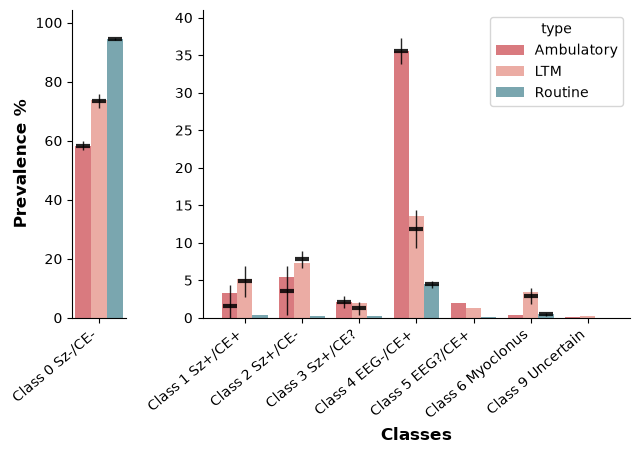

In [40]:
# Figure 3B — class frequency by TYPE on the full EEG cohort (requires eTable 5b)
if 'etable5b_full' not in globals():
    raise RuntimeError('Run eTable 5b first (defines etable5b_full).')

FIG3_PALETTE = {'Ambulatory': '#e02b35', 'LTM': '#F47C6D', 'Routine': '#368899'}
FIG3_HUE = ['Ambulatory', 'LTM', 'Routine']
FIG3_TYPE_MAP = [('AMB', 'Ambulatory'), ('LTM', 'LTM'), ('ROUTINE', 'Routine')]
n_fig3 = int(etable5b_full.iloc[0]['Overall_n_orders'])


def _fig3_num(x):
    try:
        x = float(x)
    except (TypeError, ValueError):
        return np.nan
    return x if np.isfinite(x) else np.nan


def _fig3_plot_df(numeric, suffix):
    rows = []
    for c in class_inds:
        sub = numeric.loc[numeric['Class'] == class_name(c)]
        if sub.empty:
            continue
        r = sub.iloc[0]
        for tcode, tdisp in FIG3_TYPE_MAP:
            val = _fig3_num(r.get(f'{tcode}_{suffix}', np.nan))
            ppi = _fig3_num(r.get(f'{tcode}_ppi', np.nan))
            lo = _fig3_num(r.get(f'{tcode}_ppi_lo', np.nan))
            hi = _fig3_num(r.get(f'{tcode}_ppi_hi', np.nan))
            rows.append({
                'Class': f'Class{c}',
                'type': tdisp,
                'value': (100.0 * val) if np.isfinite(val) else np.nan,
                'ppi': (100.0 * ppi) if np.isfinite(ppi) else np.nan,
                'ppi_lo': (100.0 * lo) if np.isfinite(lo) else np.nan,
                'ppi_hi': (100.0 * hi) if np.isfinite(hi) else np.nan,
            })
    return pd.DataFrame(rows)


def _overlay_ppi_errorbars(ax, plot_df, class_order):
    """Square + 95% CI at each bar center when PPI is finite."""
    n_hue = len(FIG3_HUE)
    dodge = 0.8 / n_hue
    offsets = (np.arange(n_hue) - (n_hue - 1) / 2.0) * dodge
    xmap = {cls: i for i, cls in enumerate(class_order)}
    drawn = False
    for i, tdisp in enumerate(FIG3_HUE):
        part = plot_df[plot_df['type'] == tdisp]
        xs, ys, e0, e1 = [], [], [], []
        for _, row in part.iterrows():
            if row['Class'] not in xmap or not np.isfinite(row['ppi']):
                continue
            y = float(row['ppi'])
            lo = float(row['ppi_lo']) if np.isfinite(row['ppi_lo']) else y
            hi = float(row['ppi_hi']) if np.isfinite(row['ppi_hi']) else y
            xs.append(xmap[row['Class']] + offsets[i])
            ys.append(y)
            e0.append(max(y - lo, 0.0))
            e1.append(max(hi - y, 0.0))
        if xs:
            ax.errorbar(
                xs, ys, yerr=[e0, e1], fmt='_', color='black',
                capsize=0, markersize=10, zorder=4, markeredgecolor='black',
                markeredgewidth=3, alpha=0.85, linewidth=1,
            )
            drawn = True
    return drawn


def _draw_fig3_by_type(plot_df, ylabel, fname, overlay_ppi=False):
    order0 = ['Class0']
    order1 = [f'Class{c}' for c in class_inds[1:]]
    df_class0 = plot_df[plot_df['Class'] == 'Class0']
    df_other = plot_df[plot_df['Class'] != 'Class0']
    fig = plt.figure(figsize=(7.2, 4))
    gs = fig.add_gridspec(1, 2, width_ratios=[1, 8], wspace=0.32)
    ax2 = fig.add_subplot(gs[0])
    ax1 = fig.add_subplot(gs[1])
    sns.barplot(
        x='Class', y='value', hue='type', palette=FIG3_PALETTE, hue_order=FIG3_HUE,
        order=order0, alpha=0.7, data=df_class0, ax=ax2,
    )
    sns.barplot(
        x='Class', y='value', hue='type', palette=FIG3_PALETTE, hue_order=FIG3_HUE,
        order=order1, alpha=0.7, data=df_other, ax=ax1,
    )
    if overlay_ppi:
        _overlay_ppi_errorbars(ax2, df_class0, order0)
        _overlay_ppi_errorbars(ax1, df_other, order1)
    hi_cols = ['value'] + (['ppi', 'ppi_hi'] if overlay_ppi else [])
    other_max = float(np.nanmax(df_other[hi_cols].to_numpy(dtype=float))) if len(df_other) else 1.0
    c0_max = float(np.nanmax(df_class0[hi_cols].to_numpy(dtype=float))) if len(df_class0) else 1.0
    if not np.isfinite(other_max):
        other_max = 1.0
    if not np.isfinite(c0_max):
        c0_max = 1.0
    ax1.set_ylim(0, other_max * 1.1)
    ax2.set_ylim(0, c0_max * 1.1)
    ax2.set_ylabel('Prevalence %', fontweight='bold', fontsize=12)
    ax1.set_xticks(range(len(class_inds) - 1))
    ax1.set_xticklabels([class_tick_label(c, sep=' ') for c in class_inds[1:]], rotation=40, ha='right')
    ax2.set_xticks([0])
    ax2.set_xticklabels([class_tick_label(class_inds[0], sep=' ')], rotation=40, ha='right')
    ax1.set_xlabel('Classes', fontweight='bold', fontsize=12)
    ax2.set_xlabel('')
    ax1.set_ylabel('')
    if ax2.get_legend() is not None:
        ax2.get_legend().remove()
    sns.despine()
    fig.tight_layout()
    for fn in (fname if isinstance(fname, (list, tuple)) else [fname]):
        fig.savefig(fn, dpi=300, bbox_inches='tight')
        print('saved', fn)
    plt.show()


print(f'Figure 3B  raw model by TYPE with PPI 95% CI where available (n={n_fig3})')
_draw_fig3_by_type(
    _fig3_plot_df(etable5b_full, 'model'),
    'Prevalence %',
    'manuscript/fig3b.svg',
    overlay_ppi=True,
)


### Reports per patient

Median and interquartile range (Q1–Q3) of reports per patient, overall and by recording type, for the full seizure cohort and the NLP subset. Saved as `manuscript/reports_per_patient_summary.csv`.


In [42]:
TYPE_ORDER = ['ROUTINE', 'LTM', 'AMB']


def _report_counts(orders):
    """Unique reports per patient, overall and by TYPE."""
    df = orders.dropna(subset=['PATIENT_ID']).copy()
    df['ORDER_ID'] = df['ORDER_ID'].astype(str)
    df['TYPE'] = df['TYPE'].fillna('Unknown').astype(str)
    counts = df.pivot_table(
        index='PATIENT_ID', columns='TYPE', values='ORDER_ID',
        aggfunc='nunique', fill_value=0,
    )
    for t in TYPE_ORDER:
        if t not in counts.columns:
            counts[t] = 0
    extras = [c for c in counts.columns if c not in TYPE_ORDER]
    counts = counts[TYPE_ORDER + extras]
    counts['Total'] = counts.sum(axis=1)
    return counts


def _median_iqr(s):
    q1 = float(s.quantile(0.25))
    q3 = float(s.quantile(0.75))
    return int(s.sum()), float(s.median()), q1, q3


full_counts = _report_counts(seizure_orders)
nlp_counts = _report_counts(seizure_orders[seizure_orders['nlp'].astype(bool)])
report_types = ['Total'] + TYPE_ORDER + sorted(
    (set(full_counts.columns) | set(nlp_counts.columns)) - set(TYPE_ORDER) - {'Total'}
)


def _col(counts, name):
    if name in counts.columns:
        return counts[name]
    return pd.Series(0, index=counts.index)


rows = []
for name in report_types:
    full_n, full_med, full_q1, full_q3 = _median_iqr(_col(full_counts, name))
    nlp_n, nlp_med, nlp_q1, nlp_q3 = _median_iqr(_col(nlp_counts, name))
    rows.append({
        'report_type': name,
        'full_n_reports': full_n,
        'full_median': full_med,
        'full_q1': full_q1,
        'full_q3': full_q3,
        'nlp_n_reports': nlp_n,
        'nlp_median': nlp_med,
        'nlp_q1': nlp_q1,
        'nlp_q3': nlp_q3,
    })

reports_per_patient = pd.DataFrame(rows)
display(reports_per_patient)
reports_per_patient.to_csv('manuscript/reports_per_patient_summary.csv', index=False)
print('saved manuscript/reports_per_patient_summary.csv')


,report_type,full_n_reports,full_median,full_q1,full_q3,nlp_n_reports,nlp_median,nlp_q1,nlp_q3
0,Total,16976,1.0,1.0,2.0,4213,1.0,1.0,2.0
1,ROUTINE,6722,1.0,0.0,1.0,651,0.0,0.0,1.0
2,LTM,8902,0.0,0.0,1.0,2876,1.0,0.0,2.0
3,AMB,1352,0.0,0.0,0.0,686,0.0,0.0,1.0


saved manuscript/reports_per_patient_summary.csv
